# Novel View Synthesis: NeRF vs. 3D Gaussian Splatting

## Introduction

This task is **novel view synthesis**: reconstruct a real garden from calibrated photographs and render it from held-out camera positions.

You will first run a complete **Nerfacto + Splatfacto** baseline. In **Q1**, you will implement split checks, ray compositing and reconstruction metrics. In **Q2**, you will compare both representations using the same views and metric definitions. **Q3–Q4** cover failure analysis and design choices.

Nerfacto is a practical **NeRF-family** model with hash features and a neural decoder. Splatfacto is a **3DGS** implementation based on explicit Gaussian primitives. They are not the original NeRF and 3DGS paper code. Applications include virtual tours and scene visualisation.

### Dataset — real garden photographs

The assignment includes a 17 MB `garden_512.zip` prepared from [Mip-NeRF 360](https://jonbarron.info/mipnerf360/). Extract the assignment ZIP on your computer and open its notebook in Colab. Select **Runtime → Change runtime type → T4 GPU** before uploading files. Changing the runtime type may replace the VM and remove its files. In the Colab left sidebar, open **Files → Upload** and upload `garden_512.zip` to **`/content`** before running the data cells. Keep this inner ZIP zipped; the notebook verifies and extracts it. If it is absent, the notebook instead downloads about 257 MB of source files automatically. The dataset contains **185 real garden photographs**, resized to a 512-pixel long edge, calibrated cameras, a fixed **161 training / 24 held-out** split and **50,000 sparse points**.

```
garden_512/
  images/             # real RGB photographs
  transforms.json     # cameras and explicit split lists
  seed_points.ply     # sparse initial geometry
  manifest.json       # provenance and file hashes
```

Camera poses and sparse points are supplied from COLMAP using the full capture. This is a **known-pose rendering evaluation**; only training RGB images are used to fit the radiance models.

### Evaluation metrics

We report **PSNR** and **SSIM** on the same 24 held-out RGB images. Pixel values are in [0,1].

$$\mathrm{MSE}=\frac{1}{3HW}\sum_{h,w,c}(I_{hwc}-\hat I_{hwc})^2,\qquad \mathrm{PSNR}=-10\log_{10}(\mathrm{MSE})$$

Use the same SSIM implementation for both methods: 7 × 7 window, RGB channels, `data_range=1`. Report command runtime separately; equal iterations are not equal computation. These scores use this teaching split and evaluator; do not compare them directly with published paper benchmarks or scores computed with different SSIM settings.

## Submission

Please submit:

- Your completed `tutorial08_nerf_3dgs_STUDENT.ipynb`, with outputs visible
- `garden_nvs_submission.zip`, containing the baseline images, metrics and run record
- `question_results.zip`, created by the final export cell and containing your additional tables and figures

**Checklist**

* All `###YOUR CODE HERE###` sections in Q1–Q3 are completed
* Short written answers in **Q1–Q4** are completed
* Total points: **100**; all questions are required

Keep the question numbers and section headings in your submission.

---

## Before starting — runnable tutorial

1. Select a **T4 GPU** runtime before running any cells or uploading data. Use a separate Colab runtime for each tutorial, so their output folders do not mix.
2. On the first pass, run the baseline cells in order and **stop before Q1**. Do not use **Run all** on the unfinished student notebook: its exercise placeholders intentionally raise errors.
3. Fill each `###YOUR CODE HERE###` section, replacing its `None` or `NotImplementedError`, then run Q1–Q4 in order. Reuse the baseline outputs; do not repeat model training or generation for the questions.

Download your completed notebook and both result ZIPs before ending the session. A kernel restart clears variables; recycling the VM also deletes local files.

If the baseline already finished and its files are still present after a restart, go directly to **Restore after a kernel restart**, just before Q1, then rerun your completed question cells in order.

### Imports and dataset paths

Run both cells without editing. The first defines the data helper; the second downloads, verifies and prepares the data, or uses the supplied ZIP if present. Rerunning reuses verified source files.

In [1]:
# Supplied data preparation helper; no student edits required.
from pathlib import Path
import io, json, zipfile, hashlib, sys, subprocess, time, struct, types
from collections import OrderedDict
from urllib.request import Request, urlopen
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Video

GARDEN_URL = 'https://storage.googleapis.com/gresearch/refraw360/360_v2.zip'
GARDEN_ZIP_SHA256 = '16163274ba5257aae2dd5dce6b771c16e549b4413614ee5a61f3cce494c36605'
GARDEN_SOURCE_HASHES = {'garden/images_4/DSC07956.JPG': '9dab83b11881c741f92293e35ce2fa452206237f0abf9376e9ce08b1c117f0a4', 'garden/images_4/DSC07957.JPG': '2cf56eb82779b04f1da57567d9e9a613a4df4cf36ca3b32ac40bd5e7f32961b5', 'garden/images_4/DSC07958.JPG': 'b4391d3062ded1249c586b97d2015f722216f34c19176eadca315d837b28f857', 'garden/images_4/DSC07959.JPG': '587861ed9ec0a2f1e9c57e5819fc899c4f19e1ac81b9ad862f6ad753c822af21', 'garden/images_4/DSC07960.JPG': 'd5c00bba4f3aee13e168142354ea96e5a7269635edfdbab6b4685fd09ab476cc', 'garden/images_4/DSC07961.JPG': '5b4f64f80618f574486ee149a335b2d5d880f3ee77ac39502db81245fe71652e', 'garden/images_4/DSC07962.JPG': '4cf07f505ea648807e9665dedfb51184ee6f2b3d03bb1812c817dfe3a91c8096', 'garden/images_4/DSC07963.JPG': '5ef582aa27d29a1ff8b4c9723b8460a01ca45e7f1763f40398d23846d9ce02f9', 'garden/images_4/DSC07964.JPG': '7c8469c9ce249841a07bdb5766eb66592fad16169eca0707b500cd16f5f629ec', 'garden/images_4/DSC07965.JPG': '85621fd2be8555b2e1cff45210c354c1167c8d70aae3f1603c986691f6c2753e', 'garden/images_4/DSC07966.JPG': 'b37f707485b0437db01d716b35dc3fa88b534c9aa2ddf0309a05e1b40d2d6f33', 'garden/images_4/DSC07967.JPG': '3782e4cafffd33c8f02e34b1e07c8c1738ab58e1a6835af00c26fa406c7d04b2', 'garden/images_4/DSC07968.JPG': 'aa4629f50c6a06f3c29c5b3c22f4c26c621fd59444b713ff83b1ad88862eefca', 'garden/images_4/DSC07969.JPG': 'f8147174bcf12acbb69a60ea366d3ea7f02e7aab773045d1cac3e713cabfcdb8', 'garden/images_4/DSC07970.JPG': '4547c7a5cb63cdf0c2fc0d6716a2bcd6f606c3bf1534d1d34417a3756bfd7a4b', 'garden/images_4/DSC07971.JPG': '53ed83662b6b2328b8318b081c8cf2001d8de9df5c4e08c35635eba8e5436402', 'garden/images_4/DSC07972.JPG': 'fd2b3605e7add1c3ea3666580d8c6866189e2b68d85ffd074e4d6b3586e93618', 'garden/images_4/DSC07973.JPG': 'eb0d080c41108982992cfeddc189b607c418a985d9326de90ed163d1dc236f11', 'garden/images_4/DSC07974.JPG': 'd785678702b1994a86eb3c7e38d1bc02be32b10243e2dccfbc67531f9436a696', 'garden/images_4/DSC07975.JPG': 'a79cf22ac88a28f82691804b27fde63523db354be0f7c03fb7977680d43a380b', 'garden/images_4/DSC07976.JPG': '2c5c5aae091a47eb0162148b4cd0cad6e12fe8c29f593ee6bb2bcdff72185f44', 'garden/images_4/DSC07977.JPG': 'de987911623c378420972a1fc6d4289abe57c82963b8c87fa8801d5aa6dbb5dd', 'garden/images_4/DSC07978.JPG': 'cb2c600b54e56df3087571ba6aeb289cfc9c8824a15b64ffb3c4ba229cbe1c83', 'garden/images_4/DSC07979.JPG': '77ff2cbc06371a375ecebe87ce26e171e275ff698892ad62521ab02a5823c42b', 'garden/images_4/DSC07980.JPG': '191b9aa681552a2070e50e3e7e9f667ad36f54eea03a76376cd976729881eab5', 'garden/images_4/DSC07981.JPG': '0cdbf7e88d6a418923ac1040a62cc83e192da166aa00ea2d872e83dfe1ab0215', 'garden/images_4/DSC07982.JPG': 'a37b085be5f85740ee1cad9974372a2012398edf02a0ef66768c6e37407f9589', 'garden/images_4/DSC07983.JPG': '483a484d59e9da20f3b8a97505eddff20c5ff0dda97fe167639cfca3b8d9e14b', 'garden/images_4/DSC07984.JPG': 'ab3a3d84c86ce262361a29fe92a68311096dc14dd5eccc08342145ff1ff75158', 'garden/images_4/DSC07985.JPG': '98e51e7edb5dcd692d06c7f6ebba92ff15b86c008c0521852160dd3e21e85ef3', 'garden/images_4/DSC07986.JPG': 'a416a37dd9b54cfc2313f368d8e8aa55fea9b3b7aa594f3062ae42db1db649e0', 'garden/images_4/DSC07987.JPG': 'a71ee79ff3c2172f39479f1bb96fac3d3ce4a2e9e28194a879e84419447de4c9', 'garden/images_4/DSC07988.JPG': 'e9625620633791b02fc87f02cc511a8a0e33faeeeaf96d81622f73438dd980db', 'garden/images_4/DSC07989.JPG': '169ce5968c558408138bb60d584c795bf36b614b44f7dfbc9bbc4272ce466f5e', 'garden/images_4/DSC07990.JPG': 'd489ffa601f4a7ea28e9e8ba223a85cb79b6b608e88cc4cf22acf97ef1deb715', 'garden/images_4/DSC07991.JPG': '3889c651cae45a07f8560aba22cf59821bb439fee1ae80ffaa034b48cf13152c', 'garden/images_4/DSC07992.JPG': '1262d17aa8dd4c89f54515f8063a35fbffd8d4105a996929f868e4b8762c23bd', 'garden/images_4/DSC07993.JPG': 'f002a7dc6149bcf7305df68fd5197eb0298db12d33118f46c076cf9829cb1f72', 'garden/images_4/DSC07994.JPG': 'f1edebe12a2d343b4cc92126a69d65ce572b49a497fcb51c77500d90152dd27e', 'garden/images_4/DSC07995.JPG': '4eeb381097ae27ba6106e1742d744d6b382617a86ff1fd92fbc64791a6d7e787', 'garden/images_4/DSC07996.JPG': '96bbb4fe572645593abb56bd2e2ba85449f63e6a21206a2cd5b33df657ba83b1', 'garden/images_4/DSC07997.JPG': '1b898efdad181a1c22296c31b8e5aa5a079970d135bc4e93a6a9285821f55b34', 'garden/images_4/DSC07998.JPG': '2f3520a06184113e78dd59fa7458d708de3c7d52a3e5e3c59aedaafa177a8210', 'garden/images_4/DSC07999.JPG': '68ad4d5da8788916792f36114c7e279f3158c452cf17dd537536634133d689ea', 'garden/images_4/DSC08000.JPG': '4d996eadde675f384170d4791ea8ecb53e78dad51dbb575e45dc650afbe68642', 'garden/images_4/DSC08001.JPG': 'c76303318f0d542a8d3e42b8a25b5ae0a2e70552cf0862e9a27e75dfb9db515a', 'garden/images_4/DSC08002.JPG': '7705b70c9a710b8b1d379fb67135ae3b17c7d5c5d10ba041aab1e9aabb6448e1', 'garden/images_4/DSC08003.JPG': '115c27902121b65f307b9a82436725963bd3fe2336c51e3132c47dd753f65764', 'garden/images_4/DSC08004.JPG': '994bd3a97e113672114dae3356ac81c21309c5f49d2084b9b11d42af30c4a870', 'garden/images_4/DSC08005.JPG': '6cf825a00a7f72e5125ca80caa286a47a0623c4ea55f93bf60a35c09a0ea86df', 'garden/images_4/DSC08006.JPG': 'b768b8a6a67da0d62f9155e84477c01d207cff04c88e551892de64e8ec3f7d99', 'garden/images_4/DSC08007.JPG': 'b32ffab8634aca0ad3449ff837f01e3440e95f498830bf81b5d50c17a684e45d', 'garden/images_4/DSC08008.JPG': '334e3299a4931c265745737958c0525f610a77ee02d3269fba15dd0df389dd28', 'garden/images_4/DSC08009.JPG': 'dfb80974c2b9ea23bc9d81c3c62b710004d7089b9c5bd5e930645ff816f6c5cb', 'garden/images_4/DSC08010.JPG': '1617916f459e07ebd30833f235e4cc3fea6b554861c7baea3f49e40578475c9a', 'garden/images_4/DSC08011.JPG': '3132f66f871447570a25f91f90a7adeed93a81480ca896d840fa843d07068b74', 'garden/images_4/DSC08012.JPG': '53c7e20ad7fa00f82ec41bb6d8caf8343191bc69f35172295c4030307e1db16d', 'garden/images_4/DSC08013.JPG': 'e8462034c0977015edc265034c9827ca801e07949a7a64b6ee5eb67a5ae32cc7', 'garden/images_4/DSC08014.JPG': '6f153fbeac84cd110e070347f9df1a835b7d456ed9e0a03dc5db9ecc409c88d5', 'garden/images_4/DSC08015.JPG': 'b117edcf5f23300e26babd5143a2584438f74138d39927672b54e55237be5761', 'garden/images_4/DSC08016.JPG': 'ed948c7b6c715dff4d6174d35245c0354d6910f7c3badf4656ff0972785ce814', 'garden/images_4/DSC08017.JPG': '439ba691c94a3635565f82b0e23431b27661d5c5a8ec9ac5df9a913ed1a580ba', 'garden/images_4/DSC08018.JPG': '070be6d3a082c2b74642331f1e6914100a15b569851fbaf8150bbd7ee9f5f387', 'garden/images_4/DSC08019.JPG': '2edf384e7035a5cacb3713cc3c347707f1af2ea6eb119abc3ef83e6b5d559cb4', 'garden/images_4/DSC08020.JPG': '1c1e4ed5c0a61df292684ad5a3bd0aa59fe21a1edb78277afcc623237db41e0c', 'garden/images_4/DSC08021.JPG': 'ec85c8aff2dc0d0a797b2faf6bbb437a031c10c3b5abf9bb27f689555a857bcb', 'garden/images_4/DSC08022.JPG': '0c5d454e6939d79e61fe8025ec6c72572e638ec021dc1902e0a85f6d80fe1429', 'garden/images_4/DSC08023.JPG': 'a262c6dfe7079e90b62462408b210fcb3a7778d2d9570f2c9cec04dffa6944f2', 'garden/images_4/DSC08024.JPG': '49ff49f08daf22a594ee9c16412ed8265396e5c7e2a887cdf2994a494dc37abb', 'garden/images_4/DSC08025.JPG': 'af02008943596e7064cb7fa88ebbfc63badca179892dc7994bae1904ffb78bed', 'garden/images_4/DSC08026.JPG': 'dd124a3b22cf7eab63f7d781a0711507df2a25d5529eaf1eecb5ba5f14542e18', 'garden/images_4/DSC08027.JPG': '5bd624c62178253dc646795cf4532a8aae1c4a3377730345c109163f746c348b', 'garden/images_4/DSC08028.JPG': '3c876904bbcbd2ed91412e417e036fcb7c2fb320403dd03cdcbbeb559e10a8b8', 'garden/images_4/DSC08029.JPG': '6b5f36dfe7794fd1146faef6e2b42e46fa80ab34af6b8a1cf8e6bf3b44b51ab5', 'garden/images_4/DSC08030.JPG': '37dfb4be547e013b9e8839f37baf8c686487de57eae80dafd1b4f9110711a725', 'garden/images_4/DSC08031.JPG': 'c70f6e53f99a7073ba13e3284ad2d17afdd66b7d952270f671e7891cf5770506', 'garden/images_4/DSC08032.JPG': 'adc3c201f81f383d456ec82f382136e9eaa18f3dab3cd33822a703d4ec500a87', 'garden/images_4/DSC08033.JPG': '7282a11f3daf97dfcf481da2b1d8392c6c6c2f433ce71af23a223a1dec1f8a81', 'garden/images_4/DSC08034.JPG': 'e8cc2bbf81e1f2dbe199424dbc59fd70913120c70686d29d79d8fe3bdb74280d', 'garden/images_4/DSC08035.JPG': 'a2ce5a96fc06a4511c176a38ed7e21f221d23e1e41cd2d425d526b80387c75c3', 'garden/images_4/DSC08036.JPG': 'b83fa8d6332c38fcb9ef930146b23569867ecc4db08da433659934ab213da038', 'garden/images_4/DSC08037.JPG': '35e70d8027210049ab19793561b3ab33e7cf25f9e7430205ccbac273dd5afea5', 'garden/images_4/DSC08038.JPG': '6cb480cd12b09c41b3d31ca62c08f67a5eb7275865e179326ab36c97e8fcd3e6', 'garden/images_4/DSC08039.JPG': '540a3f28f3f1ad35c71ab8e24d2a01ca2470d838ba293567ea637c43926204ed', 'garden/images_4/DSC08040.JPG': '2fbc2c727f9b36fc6fd3a4612b76e154c27a801a78d788718a2338599c652359', 'garden/images_4/DSC08041.JPG': '7001665b1edd9a9eb9b5455613f18c85c21e13bda1fa9e535ba593a4cfc44a96', 'garden/images_4/DSC08042.JPG': '87b5a3b3ac846b8e02aea6350b2ecf1a7db25338837bf26c5a180ddc3aa60080', 'garden/images_4/DSC08043.JPG': 'af863581940dd0feb4aab23ec002c4bca50ff3742c799d54464e37d4a70d1854', 'garden/images_4/DSC08044.JPG': '7dd8c53e2bf5293383651636bf2509c5fec6f54624a83e3dd6750fad1a63f055', 'garden/images_4/DSC08045.JPG': '3d4639e48d7f5c095d3d7d1230a5872a038b547d0ef73acd1026b3abcf10621c', 'garden/images_4/DSC08046.JPG': '3ee4aa0bf6233459e55425b98171be3c9645710b0b5d7bd32c575d8db10b26ff', 'garden/images_4/DSC08047.JPG': '5f6e928a8be942fdeecdd723e6ea58de0daad3aa90d8561e6cf11c988e6ca64d', 'garden/images_4/DSC08048.JPG': 'e82687c2f3dbb217309555b92f0a7ce1edf99fbcef57a9082b92eada1691d67a', 'garden/images_4/DSC08049.JPG': '82a4f3241d178be264b9219e2fb7e1085a4ffb1449e7dc360d2c2e903f3ea5e3', 'garden/images_4/DSC08050.JPG': 'd6c4534d1a213cd43f96ac28ce05daf683930578a30158e4aa092114ca0efc37', 'garden/images_4/DSC08051.JPG': 'a97110c35d73aa545799d4946123fe16e7c7799ae01943ab015f4b46339f4c45', 'garden/images_4/DSC08052.JPG': '851e8e643bc4fe99bd95fc1b51ea133899598a51de8838bba5472dd00f22e7a4', 'garden/images_4/DSC08053.JPG': 'c5f1d0341f81e2233abfc400973def8945f478ebb7f90e8b3f599ac543d608ba', 'garden/images_4/DSC08054.JPG': '73e2add65751941259b4f716629b220bd5096d713d6f26a328c96e6edb71055d', 'garden/images_4/DSC08055.JPG': 'eb6e182466a252e9e21cd1a17531686d1a777fe742967e9c8933ec2a872972c7', 'garden/images_4/DSC08056.JPG': 'ddb81fe6a5a0487286bc9b2f51276746a9fab6c737dde06c1bf570a7c83f1491', 'garden/images_4/DSC08057.JPG': 'ffef6f128c99810327683852cffc041e52b8c45df83d86333417875486cf4418', 'garden/images_4/DSC08058.JPG': '7599a716296375438d52da5bde6846db4fae937075b4c9131e46af01f9ae10fe', 'garden/images_4/DSC08059.JPG': '08cec98354f27e048cc8e0d1e0b90e774f4c02ebbe1e29fad1a5c4e9ca27eb4a', 'garden/images_4/DSC08060.JPG': '0684863ea7e80047172dc4d9ae299cdd47c2885a07ec396c085587021fa17704', 'garden/images_4/DSC08061.JPG': '1b0d50c1bde7607f7f6f013fe07e9c3bf52d88f35828344b166689bf0ce2e4ce', 'garden/images_4/DSC08062.JPG': '829e788c1d8b305c38280a5e16e8774e7e8e84a8e399a1b871c1aa15a1119197', 'garden/images_4/DSC08063.JPG': 'f34f8ee531bb8964da4b4984a8336cdefbd3b7d69646832891bc022bfb0a6983', 'garden/images_4/DSC08064.JPG': '19d92b286a2b7951e39549f7e44c8fdfc825f7bb0fae6672dd337ab9e1e2dbe5', 'garden/images_4/DSC08065.JPG': '233463d1bed4c4e41557ccfc0913c5a1c7bd6e956740d8654ca8ef9b75153320', 'garden/images_4/DSC08066.JPG': 'f2a65a0d257a37fb4f46426e4ce6bbd64ec7cb9f5235a3bebe57aaf97c02e656', 'garden/images_4/DSC08067.JPG': 'dde3912c3cf1a46710e4c6578dec28ee96a0e32cc9d869b6223d987d815608a7', 'garden/images_4/DSC08068.JPG': 'd19df8b8926b57b6ba16ec48e237d1a259c62b512c82ffaea166598e50ffcddd', 'garden/images_4/DSC08069.JPG': '473255e0d6cd249581abcc0db0575253fa09a80092d0cc0b7ec28603c9852c88', 'garden/images_4/DSC08070.JPG': 'b021332654899b3fb5807416b66dde964e0d43e63d6620ccc55a8ae444c1f39a', 'garden/images_4/DSC08071.JPG': 'f7da1c58aa7c455452b6980e883e5d6139ef05cfdc4fb33a2078da8b1fe81bd2', 'garden/images_4/DSC08072.JPG': 'e1fa521241faf9c5eacb82c748f9ae44403a0d947491911db06c645455c11197', 'garden/images_4/DSC08073.JPG': '14b343674afc3a244b8766329483a4e4d844d8ccb410f45d6f3840c8b04ce1c7', 'garden/images_4/DSC08074.JPG': '5f0ee0e0c77e16d440e46ff29eec541a3d2f05be803e796667d04fd29312291b', 'garden/images_4/DSC08075.JPG': '0d69019f3a2c448b56eef7a7e1a13e0ffa9a5403a8797df078642c9b7e26737a', 'garden/images_4/DSC08076.JPG': '466cd0d7b1d7295184d4e9ce598cfd4e2cd2aeb77544012cc9aa92c91cf80b78', 'garden/images_4/DSC08077.JPG': 'ebee0b206c759316efecddc02b3b60516742d42df5533981cd90d84099d28f87', 'garden/images_4/DSC08078.JPG': 'e4b3580fcbc2ee25d0f59bc42259028e411f6a9e084128bc73bcf797f312e407', 'garden/images_4/DSC08079.JPG': 'f1866679d4321fe88f7ba8db76c80c6bfebc3ff5f7c03294031b0362d2b233b3', 'garden/images_4/DSC08080.JPG': '3c48936d51d69df66887d78a2f14970a98de18a89b95fea848230fdc1df236e5', 'garden/images_4/DSC08081.JPG': '19f910504134b6186432d6f3a8f9e5a20663ce494bc656ca64234cca365aaf43', 'garden/images_4/DSC08082.JPG': 'b9b078f9ad9eab3fa92357744ae88becc36fce80a0f0f0e6c8a775b8f6fdf45a', 'garden/images_4/DSC08083.JPG': 'b801f81706d5d51b053ea45fbd047e2dbd84570988fdc9bc1d0124314437138e', 'garden/images_4/DSC08084.JPG': 'bd8e774116d4357a7cd59b962a416a1c2a821622bcad3ca42d17c9b59bb560f4', 'garden/images_4/DSC08085.JPG': '5b8fc5bc0e3ee8a25b249361223dff079d865decacbe84cd31a215912310ccf3', 'garden/images_4/DSC08086.JPG': 'efc2a72fc4627be241eb48e857867cc95b11799a5cf41a75e7b77d15b700dc49', 'garden/images_4/DSC08087.JPG': '85a3d3d80da280a496e30d24c0081304b894ddfdd204ea1373e6f52731d37e24', 'garden/images_4/DSC08088.JPG': '266a6163da1e71653174ad2553d02ccebf493c70f2d35959b69f5f7e702fca8d', 'garden/images_4/DSC08089.JPG': 'b9680d6ef77495f0d0d21f994642d0d2fa8e25e5fb45dec187e7c59593257b2b', 'garden/images_4/DSC08090.JPG': '6285ab95b86ebdbc59d9c837ac59e06ae68e7ac6562729ef49dc9a00cbebcf1c', 'garden/images_4/DSC08091.JPG': 'e9cb5d3bfc01181e15bdf6796e237805dcf6ab2139a2cced77e137192ca5fa09', 'garden/images_4/DSC08092.JPG': '922514a784905023191cd6eecc4cf66b4fbfc3d5377e6e625bbec5710348604b', 'garden/images_4/DSC08093.JPG': '49983211239a3003e687a5fddb798242b00628c1268c035d6ed536f2a119ee2c', 'garden/images_4/DSC08094.JPG': '853d9b4333fea8accc8a8ea9a7c82e2a47835e679bf0a676f6029e7123fc6a42', 'garden/images_4/DSC08095.JPG': '980b45997ef1cbd6c7210f9419c2a803d480b4fcf1a885247ca78e6a4e310ebe', 'garden/images_4/DSC08096.JPG': '23034982f62d68d70d1f07da6aff4f90f5bec1441e7a7a9005fa276f7c316fea', 'garden/images_4/DSC08097.JPG': '8461a92cae9e8bbe09fb29f27bb2e6a4898160de7f1d52d23eeb516d67191bee', 'garden/images_4/DSC08098.JPG': 'a599278132cb429de7fa784147c3b54f99b88b564e59102249886a16fc008648', 'garden/images_4/DSC08099.JPG': '0577122c17dfa0eff8d7ea9c082f08e65f2263a48224cbd1f0f10016645f3771', 'garden/images_4/DSC08100.JPG': '63f3767ac11bcaa8219337277512f91999aedd69570ca612335f5552cf75143d', 'garden/images_4/DSC08101.JPG': '4926d58b49237a4f1c80436938fca76373dd328bfae22ee3ae1026bce69ac813', 'garden/images_4/DSC08102.JPG': '2fcd9814cc49c57a77cf59c949935c0ba47d0bafa13688c2cb09a4a386bb1acd', 'garden/images_4/DSC08103.JPG': '280705aeb74bc89f1fbe1eead17f830b56a89396ede5f6ac8625f043c84f9469', 'garden/images_4/DSC08104.JPG': '7460c78215bc3e2d695bbcd74843f8114b57f7aedc036057a7ce956537166d0b', 'garden/images_4/DSC08105.JPG': '19871cd035d679142e84386b8b8585d3c275ebb3da67b17a6488a87c4e82fb53', 'garden/images_4/DSC08106.JPG': 'f5570a608aa5e3ed640c79fcdb8ba99e67d6894e8276bee4df4328fff593c97c', 'garden/images_4/DSC08107.JPG': '8e8e1d853405638192425bdf5fc308426a56b068d39550ec016197bcccd75f70', 'garden/images_4/DSC08108.JPG': '10656f5e9f7b10a1f7755e4e19159721a27880b348517c64449ea4da37193a15', 'garden/images_4/DSC08109.JPG': 'de350d5980f6c719a5e94358c91bca0a9e853bb03eb7808d7f86f53a25960e2a', 'garden/images_4/DSC08110.JPG': '4ee43a5817990303433b0d6da5d9049272ed9c012d9bee9f910bdf322621aba5', 'garden/images_4/DSC08111.JPG': '86e3f5d50e4c9e13af934e3cfcfd65dcc9fdb59d59d53e6786bf1636c629e542', 'garden/images_4/DSC08112.JPG': '3b772304f63db139b0302df3e06cd96353af05f4666a14efba6caadecbad6b57', 'garden/images_4/DSC08113.JPG': 'f30a816623a02d3bdaf1103d3b344e58c68d23f6a8548ee6507506702bab204d', 'garden/images_4/DSC08114.JPG': '8b139e3aca6dd99b79a2732e333dda362d17f0f363d42690bd8ae577b358b2c5', 'garden/images_4/DSC08115.JPG': '322695f5d88e6b3c46951c5d3bd3e226d46c283415b3d33db52b54e7d8f5e488', 'garden/images_4/DSC08116.JPG': '9767e93d1855b33badae1e3b41ee65ba6e8074d7ff1d22d8d8a5965b977350cf', 'garden/images_4/DSC08117.JPG': '80692c8267231d63aaa6160ff2641050cba170bfa8fabd2536c7b30350a42350', 'garden/images_4/DSC08118.JPG': '218a860435f737f1d2ceb6e75f040bb17bc8f7e484a1cd0379b2e38a3c1bed85', 'garden/images_4/DSC08119.JPG': 'c5b22c665c7be936bfe0e9c50aacc0b11205c309744354b35d8f7e73c61cfe45', 'garden/images_4/DSC08120.JPG': '58bc0bc20ad6a5286f9e87de2b0adb43df46f3ee5e59b0737e1dedda2142d07f', 'garden/images_4/DSC08121.JPG': '2be0e2e6a6707df1a3624aeffbb8a79dc6ecc2feca1824493a92bfb911a6a3c3', 'garden/images_4/DSC08122.JPG': '07435c7944f5c8f593fd39c07eefb7dd0940fe23cc4fd405498472e27c908180', 'garden/images_4/DSC08123.JPG': 'adc3b400d9a74ad09aba4c959fc0dbef3a1136f591657e0ec3bb45afc9ed26fd', 'garden/images_4/DSC08124.JPG': 'f670776534052e8b49a918be7c8e742a71204e5ef205a7df5abe4ba9c8c57491', 'garden/images_4/DSC08125.JPG': '312448623026e135120a9813bf4c20c6a6a8754047e013d31bb2438c4cfd1e91', 'garden/images_4/DSC08126.JPG': '6a4810a5aaa44dd70caf801dff20c242b99f2d964bda756e1ee30666c8c6058d', 'garden/images_4/DSC08127.JPG': 'e0f75f1dc6e1b9f6c8ff73585ed4a519cbc37659c2914d87baa54967ab60f2b1', 'garden/images_4/DSC08128.JPG': '22036c2b7a236d97c09b6f2bdf1126e12673df924f723da72e2f8c72ab1060e5', 'garden/images_4/DSC08129.JPG': 'f20994c3d15fb8e3e48fc63a44acd8f26bc97d34aad47adea2da70d5dbb43e5d', 'garden/images_4/DSC08130.JPG': '816a77b29d5b587fafdc4769331264506d5d449d4970799d8ee54974ba82a5d0', 'garden/images_4/DSC08131.JPG': '9255bec24c5ec2427b43b149d1c36aceb9eda898666cdd3452a5610368b79902', 'garden/images_4/DSC08132.JPG': 'c521b8195a50fbd1bb0f99b1a5fce0e9391ed64814224090b1847af4941bd6a3', 'garden/images_4/DSC08133.JPG': '199d5f93cd299a530a87558f3bfd788bade76985d51e7e11c78ab9c2cd04b733', 'garden/images_4/DSC08134.JPG': '469195504b9b827c953a32033800917d2dcc03d662f0d2f67fcd8e3c035c81c8', 'garden/images_4/DSC08135.JPG': '909a2498d45ca3008c25db4775ab8f75bdb254cd3de539a118b0898d0c3b836e', 'garden/images_4/DSC08136.JPG': 'e69b23bb346cb149b355984b3159935600ababf28a812872b4a915101cfdf89f', 'garden/images_4/DSC08137.JPG': '3a584046503b07321b1d6e844ac6d878cca9380a5383d1d02d597a99a62f732b', 'garden/images_4/DSC08138.JPG': 'efdaaf3930496699b35baeb4e8ac53c257c8bf442fc9ea3b0381adb628b1d4f1', 'garden/images_4/DSC08139.JPG': 'b89d060386e62c116a36bd37cc442a1f9264e5dc4de4c275101609429e67dd52', 'garden/images_4/DSC08140.JPG': '33092a1f1d2ae547ae4bfdc92b472f6db5536ae87121069d1cef4cb3e38e118a', 'garden/sparse/0/cameras.bin': '8472cc1a821db10de24155a120abfacec9268c39b562b924f8993ca0e0f299e4', 'garden/sparse/0/images.bin': '9490fc63d509ab5bcff3d85771402dd6c623809dbf0fa250a05a29bb3cea8c41', 'garden/sparse/0/points3D.bin': 'be52e343ad059bbfce00e2b22d397de75dad2d6f1ac7cf359b1b926c2b0482c8'}
_colmap = types.ModuleType("garden_colmap")
exec('# Copyright (c) 2023, ETH Zurich and UNC Chapel Hill.\n# All rights reserved.\n#\n# Redistribution and use in source and binary forms, with or without\n# modification, are permitted provided that the following conditions are met:\n#\n#     * Redistributions of source code must retain the above copyright\n#       notice, this list of conditions and the following disclaimer.\n#\n#     * Redistributions in binary form must reproduce the above copyright\n#       notice, this list of conditions and the following disclaimer in the\n#       documentation and/or other materials provided with the distribution.\n#\n#     * Neither the name of ETH Zurich and UNC Chapel Hill nor the names of\n#       its contributors may be used to endorse or promote products derived\n#       from this software without specific prior written permission.\n#\n# THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"\n# AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE\n# IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE\n# ARE DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDERS OR CONTRIBUTORS BE\n# LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR\n# CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF\n# SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS\n# INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN\n# CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE)\n# ARISING IN ANY WAY OUT OF THE USE OF THIS SOFTWARE, EVEN IF ADVISED OF THE\n# POSSIBILITY OF SUCH DAMAGE.\n#\n# Author: Johannes L. Schoenberger (jsch-at-demuc-dot-de)\n\nimport collections\n\nimport os\n\nimport struct\n\nimport numpy as np\n\nCameraModel = collections.namedtuple("CameraModel", ["model_id", "model_name", "num_params"])\n\nCamera = collections.namedtuple("Camera", ["id", "model", "width", "height", "params"])\n\nBaseImage = collections.namedtuple("Image", ["id", "qvec", "tvec", "camera_id", "name", "xys", "point3D_ids"])\n\nPoint3D = collections.namedtuple("Point3D", ["id", "xyz", "rgb", "error", "image_ids", "point2D_idxs"])\n\nclass Image(BaseImage):\n    def qvec2rotmat(self):\n        return qvec2rotmat(self.qvec)\n\nCAMERA_MODELS = {\n    CameraModel(model_id=0, model_name="SIMPLE_PINHOLE", num_params=3),\n    CameraModel(model_id=1, model_name="PINHOLE", num_params=4),\n    CameraModel(model_id=2, model_name="SIMPLE_RADIAL", num_params=4),\n    CameraModel(model_id=3, model_name="RADIAL", num_params=5),\n    CameraModel(model_id=4, model_name="OPENCV", num_params=8),\n    CameraModel(model_id=5, model_name="OPENCV_FISHEYE", num_params=8),\n    CameraModel(model_id=6, model_name="FULL_OPENCV", num_params=12),\n    CameraModel(model_id=7, model_name="FOV", num_params=5),\n    CameraModel(model_id=8, model_name="SIMPLE_RADIAL_FISHEYE", num_params=4),\n    CameraModel(model_id=9, model_name="RADIAL_FISHEYE", num_params=5),\n    CameraModel(model_id=10, model_name="THIN_PRISM_FISHEYE", num_params=12),\n}\n\nCAMERA_MODEL_IDS = dict([(camera_model.model_id, camera_model) for camera_model in CAMERA_MODELS])\n\nCAMERA_MODEL_NAMES = dict([(camera_model.model_name, camera_model) for camera_model in CAMERA_MODELS])\n\ndef read_next_bytes(fid, num_bytes, format_char_sequence, endian_character="<"):\n    """Read and unpack the next bytes from a binary file.\n    :param fid:\n    :param num_bytes: Sum of combination of {2, 4, 8}, e.g. 2, 6, 16, 30, etc.\n    :param format_char_sequence: List of {c, e, f, d, h, H, i, I, l, L, q, Q}.\n    :param endian_character: Any of {@, =, <, >, !}\n    :return: Tuple of read and unpacked values.\n    """\n    data = fid.read(num_bytes)\n    return struct.unpack(endian_character + format_char_sequence, data)\n\ndef read_cameras_binary(path_to_model_file):\n    """\n    see: src/base/reconstruction.cc\n        void Reconstruction::WriteCamerasBinary(const std::string& path)\n        void Reconstruction::ReadCamerasBinary(const std::string& path)\n    """\n    cameras = {}\n    with open(path_to_model_file, "rb") as fid:\n        num_cameras = read_next_bytes(fid, 8, "Q")[0]\n        for _ in range(num_cameras):\n            camera_properties = read_next_bytes(fid, num_bytes=24, format_char_sequence="iiQQ")\n            camera_id = camera_properties[0]\n            model_id = camera_properties[1]\n            model_name = CAMERA_MODEL_IDS[camera_properties[1]].model_name\n            width = camera_properties[2]\n            height = camera_properties[3]\n            num_params = CAMERA_MODEL_IDS[model_id].num_params\n            params = read_next_bytes(fid, num_bytes=8 * num_params, format_char_sequence="d" * num_params)\n            cameras[camera_id] = Camera(\n                id=camera_id, model=model_name, width=width, height=height, params=np.array(params)\n            )\n        assert len(cameras) == num_cameras\n    return cameras\n\ndef read_images_binary(path_to_model_file):\n    """\n    see: src/base/reconstruction.cc\n        void Reconstruction::ReadImagesBinary(const std::string& path)\n        void Reconstruction::WriteImagesBinary(const std::string& path)\n    """\n    images = {}\n    with open(path_to_model_file, "rb") as fid:\n        num_reg_images = read_next_bytes(fid, 8, "Q")[0]\n        for _ in range(num_reg_images):\n            binary_image_properties = read_next_bytes(fid, num_bytes=64, format_char_sequence="idddddddi")\n            image_id = binary_image_properties[0]\n            qvec = np.array(binary_image_properties[1:5])\n            tvec = np.array(binary_image_properties[5:8])\n            camera_id = binary_image_properties[8]\n            image_name = b""\n            current_char = read_next_bytes(fid, 1, "c")[0]\n            while current_char != b"\\x00":  # look for the ASCII 0 entry\n                image_name += current_char\n                current_char = read_next_bytes(fid, 1, "c")[0]\n            image_name = image_name.decode("utf-8")\n            num_points2D = read_next_bytes(fid, num_bytes=8, format_char_sequence="Q")[0]\n            x_y_id_s = read_next_bytes(fid, num_bytes=24 * num_points2D, format_char_sequence="ddq" * num_points2D)\n            xys = np.column_stack([tuple(map(float, x_y_id_s[0::3])), tuple(map(float, x_y_id_s[1::3]))])\n            point3D_ids = np.array(tuple(map(int, x_y_id_s[2::3])))\n            images[image_id] = Image(\n                id=image_id,\n                qvec=qvec,\n                tvec=tvec,\n                camera_id=camera_id,\n                name=image_name,\n                xys=xys,\n                point3D_ids=point3D_ids,\n            )\n    return images\n\ndef read_points3D_binary(path_to_model_file):\n    """\n    see: src/base/reconstruction.cc\n        void Reconstruction::ReadPoints3DBinary(const std::string& path)\n        void Reconstruction::WritePoints3DBinary(const std::string& path)\n    """\n    points3D = {}\n    with open(path_to_model_file, "rb") as fid:\n        num_points = read_next_bytes(fid, 8, "Q")[0]\n        for _ in range(num_points):\n            binary_point_line_properties = read_next_bytes(fid, num_bytes=43, format_char_sequence="QdddBBBd")\n            point3D_id = binary_point_line_properties[0]\n            xyz = np.array(binary_point_line_properties[1:4])\n            rgb = np.array(binary_point_line_properties[4:7])\n            error = np.array(binary_point_line_properties[7])\n            track_length = read_next_bytes(fid, num_bytes=8, format_char_sequence="Q")[0]\n            track_elems = read_next_bytes(fid, num_bytes=8 * track_length, format_char_sequence="ii" * track_length)\n            image_ids = np.array(tuple(map(int, track_elems[0::2])))\n            point2D_idxs = np.array(tuple(map(int, track_elems[1::2])))\n            points3D[point3D_id] = Point3D(\n                id=point3D_id, xyz=xyz, rgb=rgb, error=error, image_ids=image_ids, point2D_idxs=point2D_idxs\n            )\n    return points3D\n\ndef qvec2rotmat(qvec):\n    return np.array(\n        [\n            [\n                1 - 2 * qvec[2] ** 2 - 2 * qvec[3] ** 2,\n                2 * qvec[1] * qvec[2] - 2 * qvec[0] * qvec[3],\n                2 * qvec[3] * qvec[1] + 2 * qvec[0] * qvec[2],\n            ],\n            [\n                2 * qvec[1] * qvec[2] + 2 * qvec[0] * qvec[3],\n                1 - 2 * qvec[1] ** 2 - 2 * qvec[3] ** 2,\n                2 * qvec[2] * qvec[3] - 2 * qvec[0] * qvec[1],\n            ],\n            [\n                2 * qvec[3] * qvec[1] - 2 * qvec[0] * qvec[2],\n                2 * qvec[2] * qvec[3] + 2 * qvec[0] * qvec[1],\n                1 - 2 * qvec[1] ** 2 - 2 * qvec[2] ** 2,\n            ],\n        ]\n    )', _colmap.__dict__)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

class GardenRangeFile(io.RawIOBase):
    """Read ZIP byte ranges; never download the complete multi-scene archive."""
    def __init__(self):
        self.pos = 0
        self.blocks = OrderedDict()
        self.bs = 4 * 1024**2
        self.transferred = 0
        tail, content_range = self.fetch('bytes=-22', 'size', 22)
        self.size = int(content_range.split('/')[-1])
        if content_range != f'bytes {self.size - 22}-{self.size - 1}/{self.size}':
            raise RuntimeError('Unexpected archive size response')

    def fetch(self, byte_range, key, expected):
        for attempt in range(3):
            try:
                req = Request(GARDEN_URL + '?part=' + str(key),
                              headers={'Range': byte_range, 'Accept-Encoding': 'identity'})
                with urlopen(req, timeout=90) as response:
                    if response.status != 206:
                        raise RuntimeError('Server does not support partial downloads. Upload the supplied garden_512.zip and rerun.')
                    content_range = response.headers.get('Content-Range', '')
                    data = response.read(expected + 1)
                if len(data) != expected:
                    raise IOError('Incomplete or oversized range response')
                self.transferred += len(data)
                return data, content_range
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(1 + attempt)

    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos
    def seek(self, offset, whence=0):
        self.pos = offset if whence == 0 else self.pos + offset if whence == 1 else self.size + offset
        if self.pos < 0: raise ValueError('Negative seek')
        return self.pos
    def read(self, n=-1):
        end = self.size if n < 0 else min(self.pos + n, self.size)
        chunks = []
        while self.pos < end:
            block = self.pos // self.bs
            if block not in self.blocks:
                start = block * self.bs
                stop = min(start + self.bs, self.size) - 1
                data, content_range = self.fetch(f'bytes={start}-{stop}', block, stop - start + 1)
                if content_range != f'bytes {start}-{stop}/{self.size}':
                    raise IOError('Server returned the wrong byte range')
                self.blocks[block] = data
                if len(self.blocks) > 8:
                    self.blocks.popitem(last=False)
            self.blocks.move_to_end(block)
            data = self.blocks[block]
            offset = self.pos % self.bs
            amount = min(end - self.pos, len(data) - offset)
            if amount <= 0: raise EOFError('Truncated range')
            chunks.append(data[offset:offset + amount])
            self.pos += amount
        return b''.join(chunks)

def prepare_garden(root=Path('.')):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    dst = root / 'garden_512'
    archive = root / 'garden_512.zip'
    started = time.monotonic()
    mode, network_bytes = 'supplied_zip', 0
    if archive.exists():
        if file_sha256(archive) != GARDEN_ZIP_SHA256:
            raise ValueError('garden_512.zip checksum mismatch. Use the supplied ZIP, or remove it to download from the official source.')
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                if not (root / name).resolve().is_relative_to(dst.resolve()):
                    raise ValueError('Unsafe archive path')
            z.extractall(root)
        print('Verified and extracted supplied teaching ZIP.', flush=True)
    else:
        mode = 'official_partial_download'
        raw = root / '.garden_source'
        missing = [name for name, sha in GARDEN_SOURCE_HASHES.items()
                   if not (raw / name).is_file() or file_sha256(raw / name) != sha]
        print(f'Official garden data: {len(missing)} / {len(GARDEN_SOURCE_HASHES)} files to download (about 257 MB of source files).', flush=True)
        if missing:
            remote = GardenRangeFile()
            with zipfile.ZipFile(remote) as z:
                for i, name in enumerate(missing, 1):
                    data = z.read(name)
                    if hashlib.sha256(data).hexdigest() != GARDEN_SOURCE_HASHES[name]:
                        raise ValueError('Official source checksum mismatch: ' + name)
                    path = raw / name
                    path.parent.mkdir(parents=True, exist_ok=True)
                    temporary = path.with_suffix(path.suffix + '.part')
                    temporary.write_bytes(data)
                    temporary.replace(path)
                    if i % 25 == 0 or i == len(missing):
                        print(f'  Downloaded and verified {i}/{len(missing)} files', flush=True)
            network_bytes = remote.transferred
        src = raw / 'garden'
        (dst / 'images').mkdir(parents=True, exist_ok=True)
        cams = _colmap.read_cameras_binary(src / 'sparse/0/cameras.bin')
        ims = _colmap.read_images_binary(src / 'sparse/0/images.bin')
        frames = []
        for im in sorted(ims.values(), key=lambda x: x.name):
            ca = cams[im.camera_id]
            with Image.open(src / 'images_4' / im.name) as original:
                photo = original.convert('RGB')
            photo.thumbnail((512, 512), Image.Resampling.LANCZOS)
            photo.save(dst / 'images' / im.name, quality=93)
            w, h = photo.size
            if ca.model == 'PINHOLE': fx, fy, cx, cy = ca.params
            elif ca.model == 'SIMPLE_PINHOLE':
                fx, cx, cy = ca.params
                fy = fx
            else: raise ValueError('Unsupported camera model: ' + ca.model)
            R = im.qvec2rotmat()
            T = np.eye(4)
            T[:3, :3] = R.T
            T[:3, 3] = -R.T @ im.tvec
            T[:3, 1:3] *= -1
            frames.append(dict(file_path='images/' + im.name, fl_x=fx*(w/ca.width),
                               fl_y=fy*(h/ca.height), cx=cx*(w/ca.width), cy=cy*(h/ca.height),
                               w=w, h=h, transform_matrix=T.tolist(), source_id=int(im.id)))
        train = [f['file_path'] for i, f in enumerate(frames) if i % 8 != 0]
        test = [f['file_path'] for i, f in enumerate(frames) if i % 8 == 0]
        points = list(_colmap.read_points3D_binary(src / 'sparse/0/points3D.bin').values())
        idx = np.random.default_rng(42).choice(len(points), min(50000, len(points)), replace=False)
        points = [points[i] for i in sorted(idx)]
        with open(dst / 'seed_points.ply', 'wb') as f:
            f.write(('ply\nformat binary_little_endian 1.0\nelement vertex ' + str(len(points)) +
                     '\nproperty float x\nproperty float y\nproperty float z\nproperty uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n').encode())
            for point in points:
                f.write(struct.pack('<fffBBB', *point.xyz, *point.rgb))
        meta = dict(camera_model='OPENCV', k1=0, k2=0, p1=0, p2=0, frames=frames,
                    train_filenames=train, val_filenames=test, test_filenames=test, ply_file_path='seed_points.ply')
        (dst / 'transforms.json').write_text(json.dumps(meta, indent=2))
        expected_files = [f['file_path'] for f in frames] + ['transforms.json', 'seed_points.ply']
        manifest = dict(source='https://jonbarron.info/mipnerf360/', scene='garden',
                        source_photographs=len(frames), train=len(train), test=len(test),
                        max_dimension=512, seed_points=len(points), camera_model=ca.model,
                        evaluation_protocol='Known camera poses and COLMAP seed geometry provided; held-out RGB is excluded from radiance training. SfM uses the full capture, so this is not an end-to-end unseen-scene benchmark.',
                        files={name: file_sha256(dst / name) for name in expected_files},
                        raw_source_sha256=GARDEN_SOURCE_HASHES,
                        pillow_version=Image.__version__, numpy_version=np.__version__)
        (dst / 'manifest.json').write_text(json.dumps(manifest, indent=2))
    meta = json.loads((dst / 'transforms.json').read_text())
    manifest = json.loads((dst / 'manifest.json').read_text())
    for name, digest in manifest['files'].items():
        if file_sha256(dst / name) != digest: raise ValueError('Prepared file checksum mismatch: ' + name)
    assert len(meta['frames']) == 185
    assert len(meta['train_filenames']) == 161 and len(meta['test_filenames']) == 24
    assert not set(meta['train_filenames']) & set(meta['test_filenames'])
    assert all(max(f['w'], f['h']) == 512 for f in meta['frames'])
    receipt = dict(mode=mode, network_bytes=network_bytes, elapsed_seconds=round(time.monotonic()-started, 2),
                   source=GARDEN_URL, images=185, train=161, test=24, seed_points=50000,
                   note='JPEG bytes can vary with Pillow/libjpeg versions; raw source hashes are pinned.')
    (root / 'garden_data_setup.json').write_text(json.dumps(receipt, indent=2))
    print('Ready: 185 images, 161 train / 24 held-out, 512-pixel long edge, 50,000 seed points.', flush=True)
    print(f"Data setup: {receipt['elapsed_seconds']} s; downloaded {network_bytes/1e6:.1f} MB.", flush=True)
    return dst


In [2]:
DATA = prepare_garden()
OUT = Path('garden_nvs'); OUT.mkdir(exist_ok=True)
meta = json.loads((DATA/'transforms.json').read_text())
manifest = json.loads((DATA/'manifest.json').read_text())


Official garden data: 188 / 188 files to download (about 257 MB of source files).
  Downloaded and verified 25/188 files
  Downloaded and verified 50/188 files
  Downloaded and verified 75/188 files
  Downloaded and verified 100/188 files
  Downloaded and verified 125/188 files
  Downloaded and verified 150/188 files
  Downloaded and verified 175/188 files
  Downloaded and verified 188/188 files
Ready: 185 images, 161 train / 24 held-out, 512-pixel long edge, 50,000 seed points.
Data setup: 128.76 s; downloaded 241.9 MB.


#### Visualize a few samples

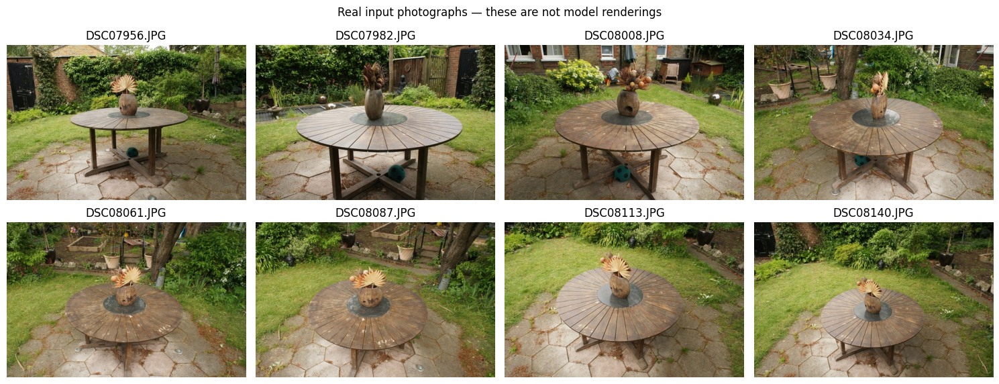

In [3]:
frames = meta['frames']
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for a, i in zip(axes.ravel(), np.linspace(0, len(frames)-1, 8).astype(int)):
    a.imshow(Image.open(DATA/frames[i]['file_path']))
    a.set_title(Path(frames[i]['file_path']).name); a.axis('off')
fig.suptitle('Real input photographs — these are not model renderings')
plt.tight_layout(); plt.show()

### Fixed training and evaluation split

Both models use exactly the same lists and calibrated world.

In [4]:
train_names = set(meta['train_filenames'])
test_names = set(meta['test_filenames'])

In [5]:
assert len(train_names) == 161 and len(test_names) == 24
assert train_names.isdisjoint(test_names)
assert train_names | test_names == {f['file_path'] for f in frames}
assert (DATA/meta['ply_file_path']).exists()
for f in frames:
    assert Image.open(DATA/f['file_path']).size == (f['w'], f['h'])
    T = np.asarray(f['transform_matrix'])
    assert np.allclose(T[3], [0, 0, 0, 1])
    assert np.isclose(np.linalg.det(T[:3,:3]), 1, atol=1e-5)
print('Shared camera and split checks passed.')

Shared camera and split checks passed.


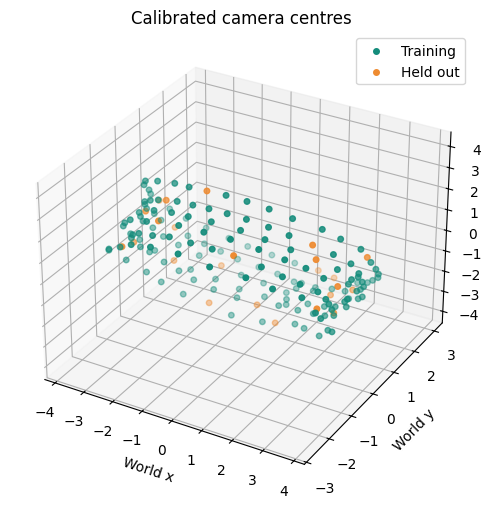

In [6]:
poses = np.asarray([f['transform_matrix'] for f in frames])
is_test = np.asarray([f['file_path'] in test_names for f in frames])
centres = poses[:, :3, 3]
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection='3d')
for mask, label, colour in [(~is_test,'Training','#148c7b'),(is_test,'Held out','#ee8b31')]:
    ax.scatter(*centres[mask].T, s=16, label=label, c=colour)
ax.set(xlabel='World x', ylabel='World y', zlabel='World z', title='Calibrated camera centres')
ax.legend(); plt.show()

### Install dependencies

Select a **T4 GPU** runtime before uploading data. The setup creates an isolated Python 3.10 environment for Nerfstudio. Allow **45–60 minutes in total** for the complete baseline, **including about 35 minutes** for installation and first-use CUDA compilation. These are planning estimates; network speed and hardware affect timing. Rerunning setup saves a separate log and duration without overwriting the first setup records.

#### Live progress

Installation and training cells show an updating status panel every 3 seconds. Training displays the latest logged step out of 3,000 and elapsed command time. Before the first step, preparation (including possible CUDA compilation) has no meaningful percentage. Full logs remain in `garden_nvs/`. Completion is shown only after the command exits successfully.

In [7]:
# Supplied live progress display; full output remains in the log files.
import html
import re
import threading
import time
from IPython.display import HTML, display

def training_step_from_log(text):
    clean = re.sub(r'\x1b\[[0-?]*[ -/]*[@-~]', '', text)
    values = re.findall(r'(?m)^\s*(\d+)\s+\(\s*\d+(?:\.\d+)?%\s*\)', clean)
    return max(map(int, values), default=None)

class LogProgress:
    def __init__(self, path, label, total=None, interval=3):
        self.path, self.label, self.total = path, label, total
        self.interval = interval
        self.started = time.perf_counter()
        self.step = None
        self.stop = threading.Event()
        self.handle = None

    def markup(self, finished=False, code=None):
        tail = ''
        if self.path.exists():
            with self.path.open('rb') as stream:
                stream.seek(max(0, self.path.stat().st_size - 65536))
                tail = stream.read().decode('utf-8', errors='replace')
        parsed = training_step_from_log(tail) if self.total else None
        if parsed is not None:
            self.step = max(self.step or 0, parsed)
        elapsed = time.perf_counter() - self.started
        clock = f'{int(elapsed//60)}m {int(elapsed%60):02d}s'
        if finished:
            status = 'Completed' if code == 0 else ('Interrupted' if code is None else f'Failed (exit {code})')
        elif self.total and self.step is not None:
            status = f'Training: step {self.step:,} / {self.total:,} ({100*self.step/self.total:.1f}%)'
        elif self.total:
            status = 'Preparing model: loading data / first-use CUDA compilation; waiting for the first training step'
        else:
            status = 'Running: downloading, installing or processing as shown in the log below'
        if finished and code == 0:
            bar = '<progress max="100" value="100" style="width:100%"></progress>'
        elif self.total and self.step is not None:
            bar = f'<progress max="{self.total}" value="{min(self.step,self.total)}" style="width:100%"></progress>'
        else:
            bar = '<progress style="width:100%"></progress>' if not finished else ''
        clean = re.sub(r'\x1b\[[0-?]*[ -/]*[@-~]', '', tail)
        last = next((line.strip() for line in reversed(clean.splitlines()) if line.strip()), 'Waiting for log output…')[-240:]
        return (f'<div style="border:1px solid #ccc;border-radius:8px;padding:12px">'
                f'<b>{html.escape(self.label)}</b> · {html.escape(status)} · Elapsed {clock}<br>{bar}'
                f'<div style="font-family:monospace;white-space:pre-wrap">{html.escape(last)}</div>'
                f'<small>Log: {html.escape(str(self.path))}</small></div>')

    def refresh(self, finished=False, code=None):
        value = HTML(self.markup(finished, code))
        if self.handle is None:
            self.handle = display(value, display_id=True)
        else:
            self.handle.update(value)

    def start(self):
        self.refresh()
        def watch():
            while not self.stop.wait(self.interval):
                self.refresh()
        self.worker = threading.Thread(target=watch, daemon=True)
        self.worker.start()
        return self

    def finish(self, code):
        self.stop.set()
        self.worker.join()
        self.refresh(finished=True, code=code)


In [9]:
import os, shutil
assert shutil.which('nvidia-smi'), 'Select a GPU runtime before setup.'
subprocess.run(['nvidia-smi'], check=True)
assert shutil.which('nvcc'), 'CUDA compiler missing; select a Colab T4 GPU runtime.'
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'uv==0.8.22'], check=True)
VENV = Path('/content/garden_ns_env') if Path('/content').exists() else Path.cwd()/'garden_ns_env'
if not (VENV/'bin/python').exists():
    subprocess.run([sys.executable,'-m','uv','venv','--seed','--python','3.10',str(VENV)],check=True)
PYTHON = str(VENV/'bin/python')
BIN = VENV/'bin'
# Colab now ships CUDA 13, but torch 2.5.1 is built for CUDA 12: build extensions with CUDA 12.5.
print('Ensuring CUDA 12.5 toolkit is installed (first time: a few minutes) ...', flush=True)
subprocess.run(['apt-get','install','-y','-q','-o','DPkg::Lock::Timeout=1800','cuda-toolkit-12-5'], check=True, stdout=subprocess.DEVNULL)
ENV = os.environ.copy()
ENV['CUDA_HOME'] = '/usr/local/cuda-12.5'  # Colab ships CUDA 13; torch 2.5.1 needs CUDA 12
ENV['PATH'] = '/usr/local/cuda-12.5/bin:' + ENV['PATH']
ENV['MAX_JOBS'] = '2'
cap = subprocess.check_output(['nvidia-smi','--query-gpu=compute_cap','--format=csv,noheader'],text=True).splitlines()[0].strip()
assert cap in ['7.5','8.0','8.6','8.9','9.0'], 'This Torch/CUDA setup does not support the allocated GPU; select a T4 runtime.'
ENV['TORCH_CUDA_ARCH_LIST'] = cap
ENV['TCNN_CUDA_ARCHITECTURES'] = cap.replace('.', '')
ENV['WANDB_MODE'] = 'disabled'
ENV['PYTHONUNBUFFERED'] = '1'
ENV['PATH'] = str(BIN) + os.pathsep + ENV['PATH']
# Compile for the allocated GPU; the free-Colab teaching target is T4.
print('Check your nvidia-smi output: this tutorial uses a T4 GPU.')
# Preserve the first setup log and timing when setup is rerun.
setup_stamp = time.time_ns()
installation_log = OUT/'installation.log'
setup_record = OUT/'setup_seconds.txt'
if installation_log.exists(): installation_log = OUT/f'installation_rerun_{setup_stamp}.log'
if setup_record.exists(): setup_record = OUT/f'setup_seconds_rerun_{setup_stamp}.txt'
setup_start = time.perf_counter()
commands = [
 [sys.executable,'-m','uv','pip','install','--python',PYTHON,
  'torch==2.5.1','torchvision==0.20.1','--index-url','https://download.pytorch.org/whl/cu124'],
 [sys.executable,'-m','uv','pip','install','--python',PYTHON,
  'numpy==1.26.4','setuptools<81','ninja','nerfstudio==1.1.5','torchmetrics==1.4.2',
  'tyro==0.8.14','scikit-image==0.24.0'],
 [sys.executable,'-m','uv','pip','install','--python',PYTHON,'--no-build-isolation',
  'git+https://github.com/NVlabs/tiny-cuda-nn.git@3c7931caab7b691c6f30dffe20952ed727d935b9#subdirectory=bindings/torch']
]
with open(installation_log,'w') as log:
    for stage, command in enumerate(commands, 1):
        print(f'Installation stage {stage}/{len(commands)} ...', flush=True)
        log.flush()
        progress = LogProgress(installation_log, f'Installation stage {stage}/{len(commands)}').start()
        result = None
        try:
            result = subprocess.run(command, env=ENV, stdout=log, stderr=subprocess.STDOUT, timeout=1800)
        finally:
            log.flush()
            progress.finish(result.returncode if result is not None else None)
        log.flush()
        if result.returncode:
            print((installation_log).read_text()[-12000:])
            result.check_returncode()
(setup_record).write_text(str(time.perf_counter()-setup_start))
subprocess.run([PYTHON,'-c','import torch,tinycudann,gsplat; print(torch.__version__,torch.cuda.get_device_name(0))'],check=True,env=ENV)
subprocess.run([PYTHON,'-m','pip','freeze'], stdout=open(OUT/'requirements_actual.txt','w'), check=True,env=ENV)

Ensuring CUDA 12.5 toolkit is installed (first time: a few minutes) ...
Check your nvidia-smi output: this tutorial uses a T4 GPU.
Installation stage 1/3 ...


Installation stage 2/3 ...


Installation stage 3/3 ...


CompletedProcess(args=['/content/garden_ns_env/bin/python', '-m', 'pip', 'freeze'], returncode=0)

### Runnable baseline: Nerfacto and Splatfacto

Use 3,000 iterations per method, disable camera optimisation, and start Splatfacto at full supplied resolution (`num_downscales=0`). Nerfacto uses **2,048 sampled rays per step** to keep the teaching run small; a Splatfacto step processes a full image. The two 3,000-step budgets therefore expose different amounts of image data. Nerfacto queries a continuous field with explicit hash features; Splatfacto projects and composites 3-D Gaussians. Both fit one captured scene.

In [10]:
MAX_STEPS = 3000
CAMERA_MODE = 'off'
SPLAT_DOWNSCALES = 0

In [11]:
assert MAX_STEPS == 3000 and CAMERA_MODE == 'off' and SPLAT_DOWNSCALES == 0

#### Supplied command logger

Run this cell to define the logging and training functions. It does not start training.

In [12]:
import threading
def load_run_records(path):
    if not path.exists():
        return []
    saved = json.loads(path.read_text())
    if not isinstance(saved, list):
        raise ValueError(f'Expected a list of run records in {path}')
    latest = {}
    for record in saved:
        if not isinstance(record, dict) or not isinstance(record.get('name'), str):
            raise ValueError(f'Invalid run record in {path}')
        latest[record['name']] = record
    return list(latest.values())

def save_run_record(path, record):
    latest = {r['name']: r for r in load_run_records(path)}
    latest[record['name']] = record
    updated = list(latest.values())
    temporary = path.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(updated, indent=2))
    temporary.replace(path)
    return updated

records = load_run_records(OUT/'run_records.json')
def run_logged(command, name):
    global records
    # Persist an unfinished attempt before launching; never reuse an old success after interruption.
    records = save_run_record(OUT/'run_records.json', dict(name=name, command=command,
        seconds=None, peak_device_memory_MiB=None, returncode=None))
    stop = threading.Event(); memory = []
    def monitor():
        while not stop.is_set():
            result = subprocess.run(['nvidia-smi','--query-gpu=memory.used',
                      '--format=csv,noheader,nounits'],capture_output=True,text=True)
            try: memory.append(max(float(v) for v in result.stdout.splitlines()))
            except ValueError: pass
            stop.wait(1)
    worker = threading.Thread(target=monitor,daemon=True); worker.start()
    t0 = time.perf_counter(); code = None
    try:
        with open(OUT/f'{name}.log','w') as log:
            total = int(command[command.index('--max-num-iterations')+1]) if '--max-num-iterations' in command else None
            progress = LogProgress(OUT/f'{name}.log', name, total=total).start()
            try:
                result = subprocess.run(command,env=ENV,stdout=log,stderr=subprocess.STDOUT)
                code = result.returncode
            finally:
                log.flush()
                progress.finish(code)
    finally:
        stop.set(); worker.join()
        rec = dict(name=name,command=command,seconds=time.perf_counter()-t0,
                   peak_device_memory_MiB=max(memory) if memory else None,returncode=code)
        records = save_run_record(OUT/'run_records.json', rec)
    if code != 0:
        print((OUT/f'{name}.log').read_text()[-12000:])
        raise RuntimeError(f'{name} failed; inspect {OUT/name}.log')
    print(name, round(rec['seconds'],1), 'seconds')

def train(method):
    command = [str(BIN/'ns-train'),method,'--data',str(DATA),
        '--output-dir',str(OUT/'checkpoints'),'--experiment-name','garden',
        '--timestamp','teaching-3k','--max-num-iterations',str(MAX_STEPS),
        '--machine.seed','42','--vis','tensorboard',
        '--steps-per-save',str(MAX_STEPS), '--steps-per-eval-all-images','1000000',
        '--pipeline.model.camera-optimizer.mode',CAMERA_MODE]
    if method == 'nerfacto':
        command += ['--pipeline.datamanager.train-num-rays-per-batch','2048']
    else:
        command += ['--pipeline.model.num-downscales',str(SPLAT_DOWNSCALES),
                    '--pipeline.datamanager.cache-images','cpu',
                    '--pipeline.datamanager.cache-images-type','uint8']
    command += ['nerfstudio-data','--downscale-factor','1',
                '--orientation-method','up','--center-method','poses',
                '--auto-scale-poses','True','--load-3D-points','True']
    run_logged(command,'train_'+method)
    candidates = list((OUT/'checkpoints/garden'/method).glob('teaching-3k/config.yml'))
    assert len(candidates)==1, candidates
    return candidates[0]

In [13]:
nerfacto_config = train('nerfacto')

train_nerfacto 175.9 seconds


#### First Splatfacto run — compilation happens here

The first run may spend **25–30 minutes** compiling the GS CUDA extension; this is already included in the total estimate above. The panel shows a preparation state until training steps are logged. Compilation is part of the measured command time whenever it occurs; cached runs may skip it. Full output is saved in `garden_nvs/train_splatfacto.log`.

In [14]:
splatfacto_config = train('splatfacto')

train_splatfacto 1542.3 seconds


In [15]:
# Both pipelines must use the identical transformation of the shared world.
a = json.loads((nerfacto_config.parent/'dataparser_transforms.json').read_text())
b = json.loads((splatfacto_config.parent/'dataparser_transforms.json').read_text())
assert np.allclose(a['transform'], b['transform'], atol=1e-6)
assert np.isclose(a['scale'], b['scale'])
print('Same world transform and scale; camera optimisation was disabled.')
display(records)

Same world transform and scale; camera optimisation was disabled.


[{'name': 'train_nerfacto',
  'command': ['/content/garden_ns_env/bin/ns-train',
   'nerfacto',
   '--data',
   'garden_512',
   '--output-dir',
   'garden_nvs/checkpoints',
   '--experiment-name',
   'garden',
   '--timestamp',
   'teaching-3k',
   '--max-num-iterations',
   '3000',
   '--machine.seed',
   '42',
   '--vis',
   'tensorboard',
   '--steps-per-save',
   '3000',
   '--steps-per-eval-all-images',
   '1000000',
   '--pipeline.model.camera-optimizer.mode',
   'off',
   '--pipeline.datamanager.train-num-rays-per-batch',
   '2048',
   'nerfstudio-data',
   '--downscale-factor',
   '1',
   '--orientation-method',
   'up',
   '--center-method',
   'poses',
   '--auto-scale-poses',
   'True',
   '--load-3D-points',
   'True'],
  'seconds': 175.9012626010001,
  'peak_device_memory_MiB': 3865.0,
  'returncode': 0},
 {'name': 'train_splatfacto',
  'command': ['/content/garden_ns_env/bin/ns-train',
   'splatfacto',
   '--data',
   'garden_512',
   '--output-dir',
   'garden_nvs/check

### Render and evaluate the same held-out views

The provided helper saves the exact command, elapsed time and sampled total device memory. Both methods must pass the shared-world assertion and use matching image sizes.

In [16]:
for method, config in [('nerfacto',nerfacto_config),('splatfacto',splatfacto_config)]:
    run_logged([str(BIN/'ns-render'),'dataset','--load-config',str(config),
        '--output-path',str(OUT/'renders'/method),'--split','test',
        '--rendered-output-names','rgb','--image-format','png'], 'render_'+method)

render_nerfacto 34.2 seconds


render_splatfacto 21.9 seconds


In [17]:
def psnr(reference, prediction):
    mse = np.mean((reference.astype(np.float64)-prediction.astype(np.float64))**2)
    return float('inf') if mse == 0 else -10*np.log10(mse)

In [18]:
assert np.isinf(psnr(np.zeros((8,8,3)),np.zeros((8,8,3))))
assert np.isclose(psnr(np.zeros((8,8,3)),np.ones((8,8,3))*0.1),20)
subprocess.run([sys.executable,'-m','pip','install','-q','scikit-image==0.25.2','pandas'],check=True)
from skimage.metrics import structural_similarity
import pandas as pd
predictions, metric_rows = {}, []
for method in ['nerfacto','splatfacto']:
    paths = list((OUT/'renders'/method/'test/rgb').rglob('*.png'))
    by_stem = {p.stem:p for p in paths}
    assert len(paths) == len(by_stem) == len(test_names), 'Missing or ambiguous rendered views'
    predictions[method] = by_stem
    for name in sorted(test_names):
        gt = np.asarray(Image.open(DATA/name).convert('RGB'), dtype=np.float32)/255
        pred = np.asarray(Image.open(by_stem[Path(name).stem]).convert('RGB'), dtype=np.float32)/255
        assert gt.shape == pred.shape, (name,gt.shape,pred.shape)
        metric_rows.append(dict(method=method,view=name,psnr=psnr(gt,pred),
           ssim=structural_similarity(gt,pred,channel_axis=-1,data_range=1.0,win_size=7)))
metrics = pd.DataFrame(metric_rows); metrics.to_csv(OUT/'per_view_metrics.csv',index=False)
display(metrics.groupby('method')[['psnr','ssim']].agg(['mean','std','min']))

psnr                           ssim                    
                 mean       std        min      mean       std       min
method                                                                  
nerfacto    24.499423  1.250824  21.091960  0.701000  0.030352  0.624301
splatfacto  26.637809  1.665361  22.120361  0.860243  0.027124  0.779151

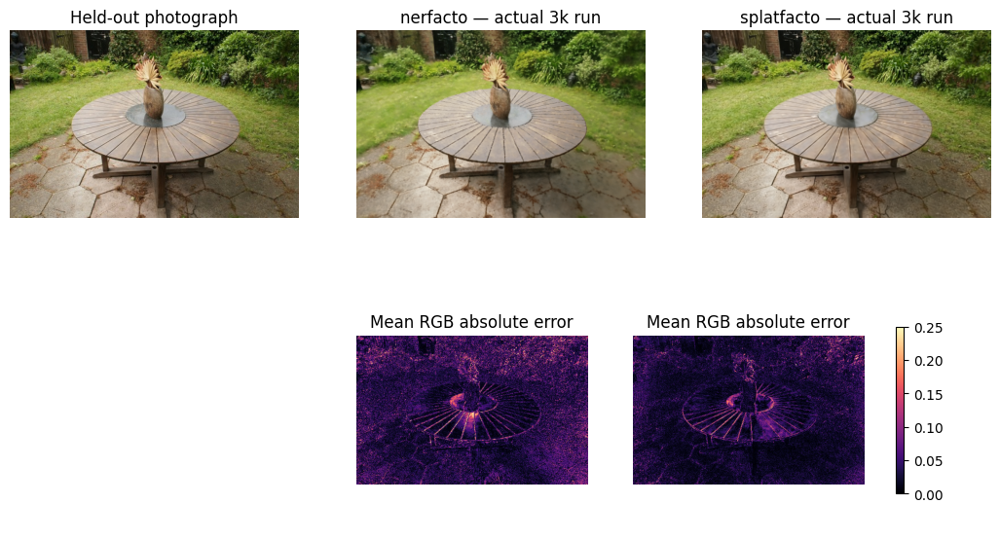

In [19]:
chosen = sorted(test_names)[len(test_names)//2]
gt = np.asarray(Image.open(DATA/chosen).convert('RGB'))/255
fig, ax = plt.subplots(2,3,figsize=(13,7))
ax[0,0].imshow(gt); ax[0,0].set_title('Held-out photograph'); ax[1,0].axis('off')
for col, method in enumerate(['nerfacto','splatfacto'],1):
    pred = np.asarray(Image.open(predictions[method][Path(chosen).stem]).convert('RGB'))/255
    ax[0,col].imshow(pred); ax[0,col].set_title(method+' — actual 3k run')
    heat = ax[1,col].imshow(np.abs(gt-pred).mean(-1),vmin=0,vmax=0.25,cmap='magma')
    ax[1,col].set_title('Mean RGB absolute error')
for a in ax.ravel(): a.axis('off')
fig.colorbar(heat,ax=ax[1,1:].tolist(),shrink=0.7)
fig.savefig(OUT/'heldout_comparison.png',dpi=150,bbox_inches='tight'); plt.show()

### Visualize the camera path and save the baseline

Both videos use the same held-out camera order and interpolation settings. Nearby-view interpolation does not guarantee good extrapolation outside the capture.

In [20]:
assert shutil.which('ffmpeg'), 'Install ffmpeg before video export.'
for method, config in [('nerfacto',nerfacto_config),('splatfacto',splatfacto_config)]:
    run_logged([str(BIN/'ns-render'),'interpolate','--load-config',str(config),
        '--output-path',str(OUT/f'{method}_path.mp4'),'--pose-source','eval',
        '--interpolation-steps','4','--frame-rate','12','--order-poses','False',
        '--rendered-output-names','rgb'],'video_'+method)
    display(Video(str(OUT/f'{method}_path.mp4'),embed=True,width=600))

video_nerfacto 96.3 seconds


video_splatfacto 23.8 seconds


In [21]:
import shutil
submission = OUT/'submission'; submission.mkdir(exist_ok=True)
for pattern in ['*.json','*.csv','*.png','*.mp4','*.txt','*.log']:
    for f in OUT.glob(pattern): shutil.copy2(f,submission/f.name)
for method, config in [('nerfacto',nerfacto_config),('splatfacto',splatfacto_config)]:
    shutil.copy2(config,submission/f'{method}_config.yml')
shutil.copy2(DATA/'manifest.json',submission/'data_manifest.json')
shutil.make_archive('garden_nvs_submission','zip',submission)
print('Saved garden_nvs_submission.zip. Keep the full working folders separately for the restore cell.')

Saved garden_nvs_submission.zip. Keep the full working folders separately for the restore cell.


### Restore after a kernel restart

Keep `garden_512/` and the **entire** `garden_nvs/` folder, including `checkpoints/`, `renders/` and `run_records.json`. The submission ZIP alone does not contain everything needed for recovery. Set `WORK_DIR` if these folders are elsewhere. After a kernel restart the files may remain; deleting or recycling the VM removes local files, so back up both folders before ending the session.

- **Baseline finished:** leave `RESTORE_MODE = 'questions'`, run the next cell directly, then rerun your completed Q1–Q4 cells in order. No training or model rendering is needed. On a new VM, restore both folders and install only the analysis dependencies if missing: `%pip install -q scikit-image==0.25.2 pandas pillow`. Do not reinstall Nerfstudio just to answer questions.
- **Both models finished, rendering did not:** set `RESTORE_MODE = 'render'`. Run the next cell, then the **Live progress** helper and **Supplied command logger** cells. Continue from **Render and evaluate the same held-out views**, skipping both training cells. If the cell reports that the Nerfstudio environment is missing, run **Install dependencies** first. Once rendering finishes, switch back to `'questions'` and run this recovery cell again.

Recovery loads saved completed models; it is not interrupted-training checkpoint continuation. Missing or unsuccessful training stages must be rerun. It never invents missing timing measurements.

In [22]:
from pathlib import Path
import json

def load_run_records(path):
    if not path.exists():
        return []
    saved = json.loads(path.read_text())
    if not isinstance(saved, list):
        raise ValueError(f'Expected a list of run records in {path}')
    latest = {}
    for record in saved:
        if not isinstance(record, dict) or not isinstance(record.get('name'), str):
            raise ValueError(f'Invalid run record in {path}')
        latest[record['name']] = record
    return list(latest.values())

def save_run_record(path, record):
    latest = {r['name']: r for r in load_run_records(path)}
    latest[record['name']] = record
    updated = list(latest.values())
    temporary = path.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(updated, indent=2))
    temporary.replace(path)
    return updated

# Run this cell after a kernel restart; no GPU training is performed.
from pathlib import Path
import json
import os, sys, subprocess, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Video
from skimage.metrics import structural_similarity

WORK_DIR = Path.cwd()  # Folder containing garden_512/ and garden_nvs/.
RESTORE_MODE = 'questions'  # Use 'render' if both models finished but rendering did not.

def restore_baseline(work_dir, require_renders=True):
    data = work_dir / 'garden_512'
    out = work_dir / 'garden_nvs'
    for required in [data/'transforms.json', data/'manifest.json', out/'run_records.json']:
        if not required.is_file():
            raise FileNotFoundError(f'Missing {required}. Restore the saved working folders first.')
    meta = json.loads((data/'transforms.json').read_text())
    manifest = json.loads((data/'manifest.json').read_text())
    frames = meta['frames']
    train_names, test_names = set(meta['train_filenames']), set(meta['test_filenames'])
    assert len(train_names) == 161 and len(test_names) == 24
    assert train_names.isdisjoint(test_names)
    assert train_names | test_names == {f['file_path'] for f in frames}
    for frame in frames:
        if not (data/frame['file_path']).is_file():
            raise FileNotFoundError(data/frame['file_path'])
    records = load_run_records(out/'run_records.json')
    by_name = {r['name']: r for r in records}
    configs, predictions = {}, {}
    expected = {Path(name).stem for name in test_names}
    for method in ['nerfacto', 'splatfacto']:
        for stage in (['train_', 'render_'] if require_renders else ['train_']):
            record = by_name.get(stage + method)
            if record is None or record.get('returncode') != 0:
                raise RuntimeError(f'{stage}{method} has no successful saved record. Complete that baseline stage first.')
            if stage == 'train_':
                for field in ['command', 'seconds', 'peak_device_memory_MiB']:
                    if field not in record:
                        raise ValueError(f'{stage}{method}: missing {field}; restore the original run_records.json.')
        config = out/'checkpoints/garden'/method/'teaching-3k/config.yml'
        checkpoint = config.parent/'nerfstudio_models/step-000002999.ckpt'
        for required in [config, checkpoint]:
            if not required.is_file() or required.stat().st_size == 0:
                raise FileNotFoundError(f'Missing {required}. Restore the model files; the submission ZIP does not include checkpoints.')
        configs[method] = config
        if not require_renders:
            continue
        paths = list((out/'renders'/method/'test/rgb').rglob('*.png'))
        by_stem = {p.stem: p for p in paths}
        if len(paths) != len(expected) or set(by_stem) != expected:
            raise ValueError(f'{method}: incomplete or ambiguous held-out renders. Rerun dataset rendering from the saved model.')
        predictions[method] = by_stem
    state = dict(DATA=data, OUT=out, meta=meta, manifest=manifest, frames=frames,
                 train_names=train_names, test_names=test_names, records=records,
                 nerfacto_config=configs['nerfacto'], splatfacto_config=configs['splatfacto'],
                 predictions=predictions)
    return state

assert RESTORE_MODE in ['questions', 'render']
globals().update(restore_baseline(WORK_DIR, require_renders=RESTORE_MODE == 'questions'))
if RESTORE_MODE == 'questions':
    print('Restored both model paths, latest run records and 24 rendered views per model. Continue with Q1–Q4; no retraining is needed.')
else:
    VENV = Path('/content/garden_ns_env') if Path('/content').exists() else WORK_DIR/'garden_ns_env'
    BIN = VENV/'bin'; PYTHON = str(BIN/'python')
    ENV = os.environ.copy()
    ENV.update(MAX_JOBS='2', WANDB_MODE='disabled', PYTHONUNBUFFERED='1')
    ENV['PATH'] = str(BIN) + os.pathsep + ENV['PATH']
    print('Restored both trained models. Run the Live progress helper and Supplied command logger cells, then continue from Render and evaluate the same held-out views. Skip both training cells.')
    if not (BIN/'ns-render').exists():
        print('The Nerfstudio environment is missing: run Install dependencies before rendering.')


Restored both model paths, latest run records and 24 rendered views per model. Continue with Q1–Q4; no retraining is needed.


---

## Q1 — Core implementation (42 pts)

Complete the missing code. Do **not** remove the `###YOUR CODE HERE###` markers. These exercises reuse the trained baseline; no second training run is required.

### Q1.1 Verify the data split (7 pts)

Construct the filename sets from the supplied metadata. Check that training and held-out filenames are disjoint and jointly cover every frame. Do not generate a new random split.

In [23]:
student_train = set(meta['train_filenames'])  # ###YOUR CODE HERE###
student_test = set(meta['test_filenames'])  # ###YOUR CODE HERE###
assert student_train.isdisjoint(student_test)
assert student_train | student_test == {f['file_path'] for f in meta['frames']}
assert len(student_train) == 161 and len(student_test) == 24
print('161 training and 24 held-out views; no overlap.')


161 training and 24 held-out views; no overlap.


### Q1.2 NeRF ray compositing (9 pts)

Implement the core front-to-back volume-rendering calculation for samples along **one ray**:

$$\alpha_i=1-e^{-\sigma_i\delta_i},\quad T_i=\prod_{j<i}(1-\alpha_j),\quad C=\sum_i T_i\alpha_i c_i.$$

Fill the three expressions below. The input colours have shape `(N, 3)`; density and interval arrays have shape `(N,)`. Use a black background.

In [24]:
def composite_ray(sigma, delta, rgb):
    alpha = 1 - np.exp(-sigma * delta)  # ###YOUR CODE HERE###
    transmittance = np.concatenate([[1.0], np.cumprod(1 - alpha)[:-1]])  # ###YOUR CODE HERE###
    colour = np.sum((transmittance * alpha)[:, None] * rgb, axis=0)  # ###YOUR CODE HERE###
    return colour
# Numerical unit examples, not rendered scene results. Background is black.
sigma = np.array([np.log(2), np.log(2)])
delta = np.ones(2)
rgb = np.array([[1.,0.,0.], [0.,0.,1.]])
assert np.allclose(composite_ray(sigma,delta,rgb), [0.5,0.,0.25])
assert np.allclose(composite_ray(np.zeros(2),delta,rgb), 0)
assert np.allclose(composite_ray(np.full(2,np.log(4)),np.full(2,0.5),rgb),[0.5,0.,0.25])
assert np.allclose(composite_ray(np.ones(2),np.zeros(2),rgb),0)
print('Ray compositing checks passed.')


Ray compositing checks passed.


### Q1.3 Preserve the comparison controls (8 pts)

Complete the expected iteration count, camera-optimisation mode and Splatfacto downscale count. Check them against the actual saved training commands.

In [25]:
expected_steps = 3000  # ###YOUR CODE HERE###
expected_camera = 'off'  # ###YOUR CODE HERE###
expected_downscales = 0  # ###YOUR CODE HERE###
def argument(command, name):
    return command[command.index(name)+1]
training_records = [r for r in records if r['name'].startswith('train_')]
assert len(training_records) == 2 and {r['name'] for r in training_records} == {'train_nerfacto', 'train_splatfacto'}, 'Run the recovery cell to load the two training records.'
assert all(r.get('returncode') == 0 for r in training_records), 'Complete both training stages first.'
for record in training_records:
    if record['name'].startswith('train_'):
        command = record['command']
        assert argument(command,'--max-num-iterations') == str(expected_steps)
        assert argument(command,'--pipeline.model.camera-optimizer.mode') == expected_camera
        if record['name'] == 'train_splatfacto':
            assert argument(command,'--pipeline.model.num-downscales') == str(expected_downscales)
print('Saved training commands satisfy the controls.')


Saved training commands satisfy the controls.


### Q1.4 Implement PSNR (15 pts)

Fill **two expressions** for RGB float arrays in [0,1]. Average squared error over all pixels and channels. Return positive infinity for identical images. Do not change the data range or crop one method differently.

In [26]:
def student_psnr(reference, prediction):
    mse = np.mean((reference.astype(np.float64) - prediction.astype(np.float64))**2)  # ###YOUR CODE HERE###
    return float('inf') if mse == 0 else -10 * np.log10(mse)  # ###YOUR CODE HERE###
assert np.isinf(student_psnr(np.zeros((8,8,3)),np.zeros((8,8,3))))
assert np.isclose(student_psnr(np.zeros((8,8,3)),np.full((8,8,3),0.1)),20)
print('PSNR checks passed.')


PSNR checks passed.


#### Q1.4 Reasoning — part of the 15 points

**Marking:** the two code expressions above carry **4 pts** total. Answer the following for the remaining **11 pts**:

1. If every RGB error has magnitude 0.1 in [0,1], derive the PSNR. (4)
2. If every error is halved, by how many dB does PSNR change? Show the MSE scaling. (4)
3. Why is it wrong to feed uint8-scale values into this formula without changing its peak-value term? (3)

**Your answer:**

1. Every error = 0.1 → MSE = 0.1² = 0.01 → PSNR = −10·log₁₀(0.01) = **20 dB**.
2. Halving every error scales MSE by (½)² = ¼: PSNR' = −10·log₁₀(MSE/4) = PSNR + 10·log₁₀4 ≈ PSNR **+ 6.02 dB** (e.g. 20 → 26.02 dB).
3. The formula is really PSNR = 10·log₁₀(MAX²/MSE) with MAX = 1 for [0,1] data. With uint8 values the MSE is 255² times larger, so keeping MAX = 1 shifts every score down by 20·log₁₀255 ≈ 48.13 dB (usually giving negative PSNR). Either use MAX = 255 or convert to [0,1] first; also cast to float to avoid uint8 overflow in the subtraction.

### Q1.5 Match a rendered view to its photograph (3 pts)

The prediction dictionary is keyed by filename stem. Complete the lookup key, so a held-out photograph is paired with its own rendered camera view.

In [27]:
def prediction_path(method, view):
    key = Path(view).stem  # ###YOUR CODE HERE###
    return predictions[method][key]
for method in ['nerfacto','splatfacto']:
    assert prediction_path(method,sorted(student_test)[0]).is_file()
print('View matching passed.')


View matching passed.


---

## Q2 — Representations, metrics & robustness (30 pts)

**Q2.1** evaluates both methods on common held-out views. **Q2.2** joins quality and cost records. **Q2.3** is a short written question. Use actual baseline renders and logs; do not retrain either model.

### Q2.1 Common evaluation and paired-view comparison (20 pts)

Calculate PSNR and SSIM for **both methods on all 24 held-out views** (**8 pts**). Compute the **paired per-view PSNR difference (Splatfacto minus Nerfacto)** and report its mean, sample standard deviation, positive count and ties (**8 pts**). Explain why the common evaluator and paired comparison matter (**4 pts**, below).

Pair the methods by view to examine differences hidden by global averages. CSV export is supplied.

Use RGB, identical image sizes, `data_range=1` and a 7 × 7 SSIM window. Hint: `structural_similarity(..., channel_axis=-1, ...)`. Do not compare a training score from one method against a held-out score from the other.

Use sample standard deviation (`ddof=1`), positive differences (`delta > 0`) for wins, and strict equality (`delta == 0`) for ties.

In [28]:
QOUT = Path('question_results'); QOUT.mkdir(exist_ok=True)
student_rows = []
for method in ['nerfacto','splatfacto']:
    for view in sorted(student_test):
        gt = np.asarray(Image.open(DATA/view).convert('RGB'),dtype=np.float32)/255
        pred = np.asarray(Image.open(prediction_path(method,view)).convert('RGB'),dtype=np.float32)/255
        assert gt.shape == pred.shape
        score = student_psnr(gt, pred)  # ###YOUR CODE HERE###
        ssim = structural_similarity(gt, pred, channel_axis=-1, data_range=1.0, win_size=7)  # ###YOUR CODE HERE###
        student_rows.append(dict(method=method,view=view,psnr=score,ssim=ssim))
student_metrics = pd.DataFrame(student_rows)
assert len(student_metrics) == 48
student_metrics.to_csv(QOUT/'independent_metrics.csv',index=False)
display(student_metrics.groupby('method')[['psnr','ssim']].agg(['mean','std','min']))
paired = student_metrics.pivot(index='view',columns='method',values='psnr')
assert set(paired.index)==student_test and not paired.isna().any().any()
paired['delta_psnr'] = paired['splatfacto'] - paired['nerfacto']  # ###YOUR CODE HERE###
d = paired['delta_psnr']
paired_summary = dict(mean_delta=float(d.mean()), std_delta=float(d.std(ddof=1)),
                      splat_wins=int((d > 0).sum()), ties=int((d == 0).sum()))  # ###YOUR CODE HERE###
assert all(v is not None for v in paired_summary.values())
paired.to_csv(QOUT/'paired_view_differences.csv')
display(paired_summary)


psnr                           ssim                    
                 mean       std        min      mean       std       min
method                                                                  
nerfacto    24.499423  1.250824  21.091960  0.701000  0.030352  0.624301
splatfacto  26.637809  1.665361  22.120361  0.860243  0.027124  0.779151

{'mean_delta': 2.1383860240064863,
 'std_delta': 0.9234270186193682,
 'splat_wins': 23,
 'ties': 0}

**Q2.1 observation:** Why use the same evaluator and pair results by view? Does the better global mean imply a win on every view?

**Your answer:**

Using one evaluator (same PSNR code, same SSIM settings: RGB, 7×7 window, `data_range=1`, same 24 held-out views at the same size) means the difference comes from the models, not from metric choices. Pairing by view removes shared view difficulty: per-view PSNR std is 1.25–1.67 dB for each method, but the paired difference is much more stable (mean **+2.14 dB** for Splatfacto, sample std **0.92 dB**). Splatfacto wins on **23 of 24** views with **0 ties**, so the better global mean does **not** mean it wins every view: Nerfacto is still better on one view. The paired view shows how consistent the gap is, which two separate means cannot.

### Q2.2 Quality and cost (6 pts)

Compute mean PSNR/SSIM **per method** and join the measured training-command runtime and sampled total device memory (**4 pts**). In the answer below, state the units and explain the timing limitation (**2 pts**). The command timer includes process startup, data loading and any first-use compilation. These records do not measure compilation and pure training separately: label their components as unavailable and do not claim pure-training speed from the total.

In [29]:
quality = student_metrics.groupby('method')[['psnr', 'ssim']].mean()  # ###YOUR CODE HERE###
costs = pd.DataFrame([dict(method=r['name'].removeprefix('train_'), command_seconds=r['seconds'],
                         peak_device_memory_MiB=r['peak_device_memory_MiB'])
                     for r in records if r['name'].startswith('train_')]).set_index('method')
assert costs.index.is_unique and set(costs.index) == {'nerfacto', 'splatfacto'}, 'Run the recovery cell to load one record per model.'
summary = quality.join(costs)
summary.to_csv(QOUT/'quality_and_cost.csv')
display(summary)


,psnr,ssim,command_seconds,peak_device_memory_MiB
method,,,,
nerfacto,24.499423,0.701000,175.901263,3865.0
splatfacto,26.637809,0.860243,1542.251757,1411.0


**Q2.2 observation:** State the time and memory units. Why does this table not measure pure-training speed?

**Your answer:**

`command_seconds` is wall-clock time in **seconds**; `peak_device_memory_MiB` is the peak **total** GPU memory used on the device in **MiB**, sampled about once per second by `nvidia-smi` (short peaks can be missed, and it includes the CUDA context, not only the model). Measured: Nerfacto 176 s / 3,865 MiB, Splatfacto 1,542 s / 1,411 MiB. The time covers the whole `ns-train` command: start-up, data loading/caching, **first-use CUDA compilation** (the gsplat kernels were compiled during this Splatfacto run, which explains most of its ~25 min) and saving. Compilation and pure-training time were not recorded separately, so they are **unavailable**; the table does not show that Splatfacto trains ~9× slower.

### Q2.3 Short answer (4 pts)

Does an equal iteration count provide a fair speed comparison? Which costs should a longer benchmark separate?

**Your answer:**

No. 3,000 Nerfacto steps use 2,048 rays each, while one Splatfacto step renders a whole image, so the methods see different amounts of data and do different work per step. A fair benchmark should compare quality at equal wall-clock time (or a quality-vs-time curve) and separately record: installation/compilation, data loading/caching, pure training time per step, evaluation/rendering time (FPS), and peak model memory and file size.

---

## Q3 — Failure analysis and local evaluation (18 pts)

Use your rendered views to connect metric differences with visible reconstruction errors.

### Q3.1 Failure cases (6 pts)

Choose **two difficult held-out views**. Plot ground truth, Nerfacto and Splatfacto for each. Discuss one local failure in each view; do not just repeat the mean PSNR ranking.

**Your answer:**

The two hardest views (lowest mean PSNR) are **DSC07988** and **DSC07964**; both look outward toward the far background, which fewer training cameras cover well.
- **DSC07988:** Nerfacto turns the trees and sky above the brick wall into a smeared green-white blur, and the roof/chimney almost disappears; the grass and paving lose texture. Splatfacto keeps the house and wall, but the treetops against the sky are blotchy, with visible elongated Gaussians.
- **DSC07964:** Nerfacto blurs the background building (windows become soft smudges) and the thin pergola/planter structures on the left. Splatfacto is much sharper on the building and the bushes, but thin structures (pergola poles, small branches) are still broken or smeared.

Both methods do well on the central table, so the PSNR loss comes mainly from distant, high-frequency background regions.

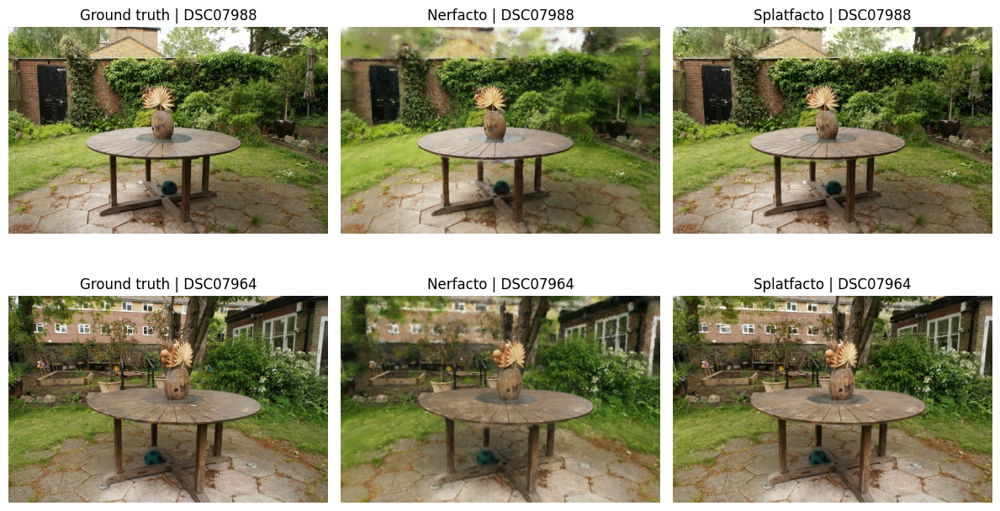

In [30]:
difficult = student_metrics.groupby('view')['psnr'].mean().nsmallest(2).index.tolist()
fig, axes = plt.subplots(2,3,figsize=(12,7))
for row, view in enumerate(difficult):
    panels=[Image.open(DATA/view)]+[Image.open(prediction_path(m,view)) for m in ['nerfacto','splatfacto']]
    for col,(im,label) in enumerate(zip(panels,['Ground truth','Nerfacto','Splatfacto'])):
        axes[row,col].imshow(im); axes[row,col].set_title(label+' | '+Path(view).stem); axes[row,col].axis('off')
plt.tight_layout();fig.savefig(QOUT/'failure_cases.png',dpi=120);plt.show()


### Q3.2 Local reconstruction errors (8 pts)

The baseline averages over full images. On one held-out view, evaluate the **same central crop** for both methods and produce error heatmaps with the **same colour scale**. Compare the local result with the full-view PSNR. Explain one limitation of selecting a crop after seeing the output.

**Your answer:**

Fixed rule: central 50% crop (y83:249, x128:384) of view **DSC08052**, same 0–0.25 colour scale for both maps.

| | full PSNR | crop PSNR | crop SSIM |
|---|---|---|---|
| Nerfacto | 25.16 dB | 25.45 dB | 0.793 |
| Splatfacto | 27.96 dB | 26.67 dB | 0.870 |

The gap shrinks from **2.80 dB** on the full view to **1.22 dB** in the crop: on the central table both methods are closer, and most of Splatfacto's advantage comes from the background outside the crop (its crop PSNR is even lower than its full-view PSNR). The heatmaps show errors concentrated on the table's plank gaps/edges and the bright rim of the centre disc (high-frequency edges); Nerfacto has stronger errors on the bright rim and in front of the vase. **Limitation:** if the crop is chosen *after* seeing the outputs, it is easy to pick a region that favours one method (cherry-picking), and one crop on one view is not statistically representative. The rule should be fixed in advance (as here) and applied to all views.

Save your results under `QOUT` so they enter `question_results.zip`: `QOUT/'local_metrics.csv'` and `QOUT/'local_errors.png'`.

,method,view,crop,full_psnr,crop_psnr,crop_ssim
0,nerfacto,images/DSC08052.JPG,"y83:249,x128:384",25.160101,25.445659,0.793499
1,splatfacto,images/DSC08052.JPG,"y83:249,x128:384",27.956103,26.668603,0.870057


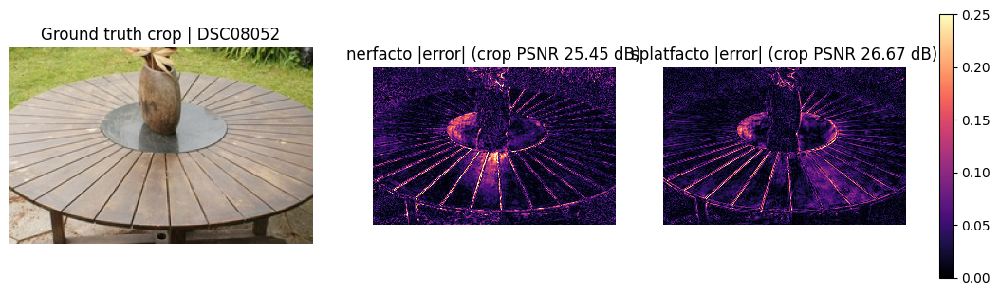

In [31]:
# Implement the common-crop evaluation and error maps described above.
# ###YOUR CODE HERE###
# Crop rule fixed in advance: central 50% x 50% of the median-named held-out view.
view = sorted(student_test)[len(student_test)//2]
gt = np.asarray(Image.open(DATA/view).convert('RGB'), dtype=np.float32)/255
H, W = gt.shape[:2]
ys, xs = slice(H//4, H//4 + H//2), slice(W//4, W//4 + W//2)
local_rows, errors = [], {}
for method in ['nerfacto', 'splatfacto']:
    pred = np.asarray(Image.open(prediction_path(method, view)).convert('RGB'), dtype=np.float32)/255
    g, p = gt[ys, xs], pred[ys, xs]
    errors[method] = np.abs(g - p).mean(-1)
    local_rows.append(dict(method=method, view=view, crop=f'y{ys.start}:{ys.stop},x{xs.start}:{xs.stop}',
        full_psnr=student_psnr(gt, pred), crop_psnr=student_psnr(g, p),
        crop_ssim=structural_similarity(g, p, channel_axis=-1, data_range=1.0, win_size=7)))
local_metrics = pd.DataFrame(local_rows)
local_metrics.to_csv(QOUT/'local_metrics.csv', index=False)
display(local_metrics)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
ax[0].imshow(gt[ys, xs]); ax[0].set_title('Ground truth crop | ' + Path(view).stem)
for a, method in zip(ax[1:], ['nerfacto', 'splatfacto']):
    heat = a.imshow(errors[method], vmin=0, vmax=0.25, cmap='magma')  # same colour scale
    a.set_title(f'{method} |error| (crop PSNR {local_metrics.set_index("method").loc[method, "crop_psnr"]:.2f} dB)')
for a in ax: a.axis('off')
fig.colorbar(heat, ax=ax[1:].tolist(), shrink=0.8)
fig.savefig(QOUT/'local_errors.png', dpi=120, bbox_inches='tight'); plt.show()


### Q3.3 Limitations (short, 4 pts)

Name one limitation of deploying this reconstruction as a virtual tour.

**Your answer:**

The model only works well near the captured camera path. A virtual-tour visitor who moves far outside the training views (e.g. behind the table or to the far background) will see floaters, holes and blur. Also, the scene is static with fixed lighting, so moving objects, changing light or a new season need a new capture.

---

## Q4 — Design & analysis: beyond the baseline (10 pts)

Write a short paragraph for each question.

### Q4.1 Representation choice (4 pts)

**Question:** When might you prefer a NeRF-family field or an explicit Gaussian representation? Discuss rendering, storage and the measurements in your run.

**Your answer:**

Prefer **explicit Gaussians (Splatfacto/3DGS)** when you need real-time rendering (rasterization is fast, good for interactive viewers and VR) and sharp detail. In this run it gave clearly better quality (26.64 dB / 0.860 SSIM vs 24.50 dB / 0.701, winning 23/24 views) and a lower sampled peak memory (1,411 vs 3,865 MiB). The cost is storage that grows with the number of Gaussians (often hundreds of MB for large scenes) and a one-time CUDA compile (its 1,542 s command time is mostly compilation). Prefer a **NeRF-family field (Nerfacto)** when compact storage, smooth geometry/depth, or graceful filling of poorly observed regions matter more than speed: the hash grid + small MLP is compact and its 3k-step run took only 176 s here, but every pixel needs many network queries along the ray, so rendering is slow and, at this budget, blurrier in the background.

### Q4.2 Data and geometry (4 pts)

**Question:** Why must resized images have resized camera intrinsics? Why is this experiment not an end-to-end training-only reconstruction benchmark?

**Your answer:**

Intrinsics (fx, fy, cx, cy) are in pixels. If the image is downsized by a factor s, each pixel covers s× more of the scene, so the intrinsics must be multiplied by the same s; otherwise rays are cast in the wrong directions and the images do not line up with the 3D scene, ruining training and evaluation. This is not an end-to-end benchmark because the camera poses and the seed points come from COLMAP run on **all 185 photos, including the 24 held-out ones**. So the test views helped build the geometry; only their RGB pixels are excluded from training. A real end-to-end test would run SfM on training images only and also estimate the test poses.

### Q4.3 Synthesis (2 pts)

**Question:** With one extra free-GPU session, which single controlled follow-up would you try first, and why?

**Your answer:**

Train both methods to an **equal wall-clock budget** (e.g. same minutes of pure training after compilation is cached), with everything else unchanged, and log PSNR on the held-out views over time. This answers the question the equal-iteration run cannot: which representation gives better quality for the same compute.

### Export question results

Run after completing Q1–Q3, then download `question_results.zip` from the Colab file pane. The earlier baseline ZIP does not include these question results. Written answers remain in your completed notebook.

In [32]:
import shutil
question_archive = shutil.make_archive('question_results','zip',QOUT)
print('Saved',question_archive)


Saved /content/question_results.zip


### References
- [Mip-NeRF 360: real garden capture](https://jonbarron.info/mipnerf360/)
- [Original NeRF paper and demonstrations](https://www.matthewtancik.com/nerf)
- [Original 3D Gaussian Splatting paper and demonstrations](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/)
- [Nerfacto documentation](https://docs.nerf.studio/nerfology/methods/nerfacto.html)
- [Splatfacto documentation](https://docs.nerf.studio/nerfology/methods/splat.html)
- [Nerfstudio installation](https://docs.nerf.studio/quickstart/installation.html)

Implementation: Nerfstudio 1.1.5 (Nerfacto and Splatfacto).